# EDA: characterise the Corpus

Exploratory data analysis of the SEC EDGAR Corpus supplied with the assessment.
Every analysis loads Filings through the `edgar_rag` Corpus seam, the same code the
indexer and API will use, and ends with a **so the design does X** conclusion.
Findings are collected in [`docs/findings.md`](../../docs/findings.md).

This file is the source of truth (jupytext percent format). The paired `.ipynb`
is generated with `make eda` and is never edited by hand.

In [1]:
import json
import re
from collections import Counter, defaultdict
from functools import cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tiktoken
from IPython.display import HTML, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from edgar_rag.corpus import (
    DEFAULT_CORPUS_DIR,
    TRACKED_MIN_QUARTERS,
    UNSECTIONED,
    check_manifest,
    consecutive_quarters,
    load_corpus,
    load_sector_table,
)
from edgar_rag.financial_facts import extract_financial_facts
from edgar_rag.sec_reference import load_company_facts

filings = load_corpus()
print(f"{len(filings)} Filings from {len({f.ticker for f in filings})} Companies")

246 Filings from 54 Companies


## 1. Inventory and coverage

### 1.1 Filings per Company and the coverage grid

How many Filings does each Company have, of which Form Type, and in which Calendar
Quarters? Calendar Quarter is taken from the header as written. Filings whose header
has no Calendar Quarter are counted in a separate column; deriving their Report
Period is a later analysis.

In [2]:
df = pd.DataFrame(
    {
        "ticker": f.ticker,
        "company": f.company,
        "form_type": f.form_type,
        "calendar_quarter": f.calendar_quarter,
        "report_period": f.report_period,
        "filing_date": f.filing_date,
    }
    for f in filings
)

per_company = (
    df.pivot_table(index="ticker", columns="form_type", values="company", aggfunc="count")
    .fillna(0)
    .astype(int)
)
per_company["total"] = per_company.sum(axis=1)
per_company = per_company.sort_values(["total", "10-Q"], ascending=False)
per_company.T

ticker,DIS,JNJ,AAPL,AMZN,MSFT,NVDA,TSLA,XOM,KO,PFE,...,PG,RTX,SBUX,T,TGT,TMO,UPS,V,VZ,WMT
form_type,,,,,,,,,,,,,,,,,,,,,
10-K,4,5,4,4,4,4,4,4,3,3,...,1,1,1,1,1,1,1,1,1,1
10-Q,13,12,12,12,12,12,12,12,12,12,...,0,0,0,0,0,0,0,0,0,0
total,17,17,16,16,16,16,16,16,15,15,...,1,1,1,1,1,1,1,1,1,1


In [3]:
filings_per_company = Counter(per_company["total"])
pd.DataFrame(
    sorted(filings_per_company.items(), reverse=True),
    columns=["Filings per Company", "Companies"],
).set_index("Filings per Company").T

Filings per Company,17,16,15,14,8,4,2,1
Companies,2,6,3,1,1,2,2,37


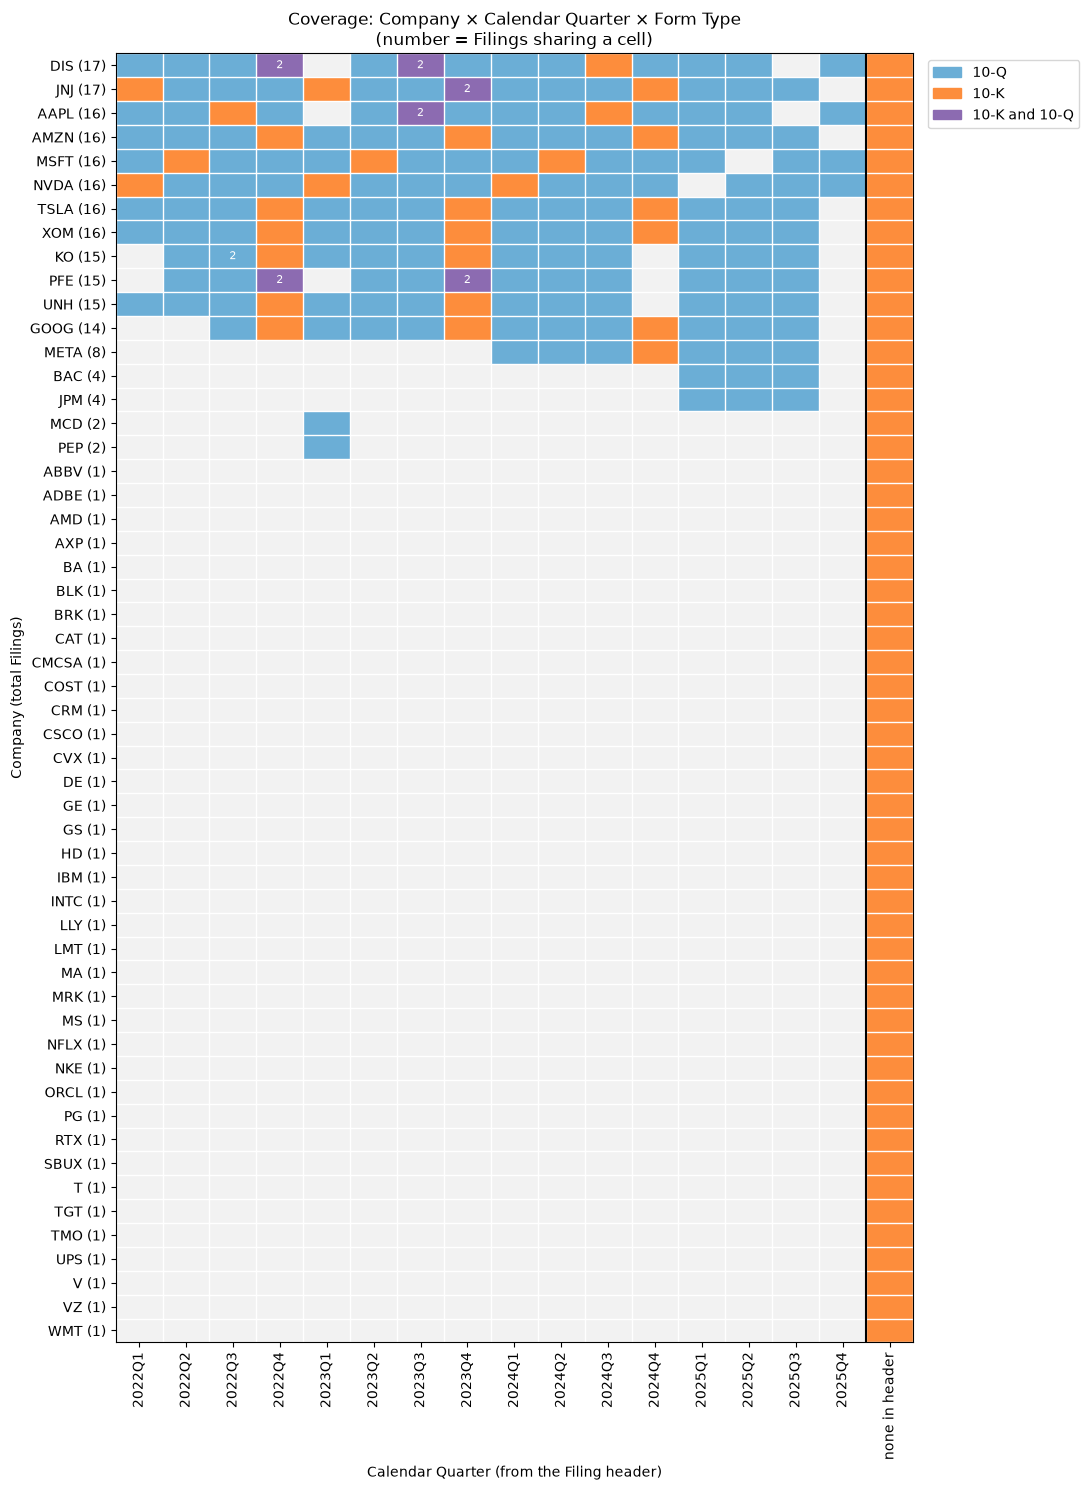

In [4]:
NO_QUARTER = "none in header"

known_quarters = df["calendar_quarter"].dropna()
quarters = [str(q) for q in pd.period_range(known_quarters.min(), known_quarters.max(), freq="Q")]
columns = quarters + [NO_QUARTER]
tickers = list(per_company.index)

# Cell code: 0 = no Filing, 1 = 10-Q only, 2 = 10-K only, 3 = both.
codes = np.zeros((len(tickers), len(columns)), dtype=int)
counts = np.zeros_like(codes)
for f in filings:
    row = tickers.index(f.ticker)
    col = columns.index(f.calendar_quarter or NO_QUARTER)
    codes[row, col] |= 2 if f.form_type == "10-K" else 1
    counts[row, col] += 1

colours = ["#f2f2f2", "#6baed6", "#fd8d3c", "#8c6bb1"]
fig, ax = plt.subplots(figsize=(11, 15))
ax.imshow(codes, cmap=ListedColormap(colours), vmin=0, vmax=3, aspect="auto")
for r, c in zip(*np.nonzero(counts > 1), strict=True):
    ax.text(c, r, counts[r, c], ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(range(len(columns)), columns, rotation=90)
ax.set_yticks(range(len(tickers)), [f"{t} ({per_company.loc[t, 'total']})" for t in tickers])
ax.set_xticks(np.arange(-0.5, len(columns)), minor=True)
ax.set_yticks(np.arange(-0.5, len(tickers)), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)
ax.axvline(len(quarters) - 0.5, color="black", linewidth=1.5)
ax.set_xlabel("Calendar Quarter (from the Filing header)")
ax.set_ylabel("Company (total Filings)")
ax.set_title("Coverage: Company × Calendar Quarter × Form Type\n(number = Filings sharing a cell)")
ax.legend(
    handles=[
        Patch(color=colour, label=label)
        for colour, label in zip(colours[1:], ["10-Q", "10-K", "10-K and 10-Q"], strict=True)
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)
fig.tight_layout()
plt.show()

In [5]:
missing_quarter = df[df["calendar_quarter"].isna()]
shared_cells = int((counts[:, : len(quarters)] > 1).sum())
print(f"Filings with no Calendar Quarter in the header: {len(missing_quarter)}")
print(f"Companies with exactly one Filing: {(per_company['total'] == 1).sum()}")
print(f"Companies with 4 or more Filings: {(per_company['total'] >= 4).sum()}")
print(f"Company × Calendar Quarter cells holding more than one Filing: {shared_cells}")

Filings with no Calendar Quarter in the header: 54
Companies with exactly one Filing: 37
Companies with 4 or more Filings: 15
Company × Calendar Quarter cells holding more than one Filing: 7


**What the grid shows**

- Coverage is very uneven. 12 Companies have 14–17 Filings spread over 2022Q1–2025Q4,
  META has 8, JPM and BAC have 4, MCD and PEP have 2, and the remaining 37 Companies
  have a single 10-K.
- Every Company has exactly one Filing with no Calendar Quarter (or Report Period) in
  its header: its most recent 10-K (filed between 2024 and 2026, plus GE's from 2015).
  For the 37 single-Filing Companies that is their only Filing, so they cannot be
  placed on the time axis from the header alone.
- Several Company × Calendar Quarter cells hold two Filings (e.g. Coca-Cola's two
  2022Q3 Filings), so Calendar Quarter cannot be a unique key.
- Coverage starts in 2022Q1, a year before the brief's "2023–2025".

**So the design does:**

- Treat Company coverage as first-class metadata: classify each Company as a Tracked
  Company (quarterly Filings across years, trend questions answerable) or a Snapshot
  Company (point-in-time only), and have the Answer Call state plainly when coverage
  limits an answer.
- Filter retrieval on Company and Report Period metadata instead of relying on
  similarity alone, so a trend question about a Tracked Company is not crowded out by
  one-off 10-Ks, and a comparison across Snapshot Companies retrieves each of them.
- Derive a Report Period for every Filing whose header lacks one (next analysis), and
  never use Calendar Quarter as a key.

### 1.2 Tracked and Snapshot Companies

A trend question ("How has NVIDIA's revenue changed over the last two years?") needs
a run of consecutive quarters. For each Company the next cell counts the longest run
of consecutive quarter-ends its Filings cover, on the Report Period (a 10-K counts as
its fiscal year's fourth quarter-end). A Company is a **Tracked Company** when that run
is at least eight quarters (two years) and a **Snapshot Company** otherwise.

In [6]:
by_ticker = {}
for f in filings:
    by_ticker.setdefault(f.ticker, []).append(f)

coverage = pd.DataFrame(
    {
        "ticker": ticker,
        "filings": len(fs),
        "10-K": sum(f.form_type == "10-K" for f in fs),
        "10-Q": sum(f.form_type == "10-Q" for f in fs),
        "first report period": min(f.report_period for f in fs),
        "last report period": max(f.report_period for f in fs),
        "consecutive quarters": consecutive_quarters(fs),
        "coverage": fs[0].coverage,
    }
    for ticker, fs in by_ticker.items()
).set_index("ticker")
coverage = coverage.sort_values(["consecutive quarters", "filings"], ascending=False)
print(f"Tracked/Snapshot cut-off: {TRACKED_MIN_QUARTERS} consecutive quarters")
coverage["coverage"].value_counts().to_frame("Companies").T

Tracked/Snapshot cut-off: 8 consecutive quarters


coverage,snapshot,tracked
Companies,41,13


In [7]:
coverage[coverage["filings"] > 1]

,filings,10-K,10-Q,first report period,last report period,consecutive quarters,coverage
ticker,,,,,,,
DIS,17,4,13,2022-01-01,2025-12-27,17,tracked
JNJ,17,5,12,2022-01-02,2025-12-28,17,tracked
AAPL,16,4,12,2022-03-26,2025-12-27,16,tracked
AMZN,16,4,12,2022-03-31,2025-12-31,16,tracked
MSFT,16,4,12,2022-03-31,2025-12-31,16,tracked
NVDA,16,4,12,2022-01-30,2025-10-26,16,tracked
TSLA,16,4,12,2022-03-31,2025-12-31,16,tracked
XOM,16,4,12,2022-03-31,2025-12-31,16,tracked
KO,15,3,12,2022-04-01,2025-09-26,15,tracked


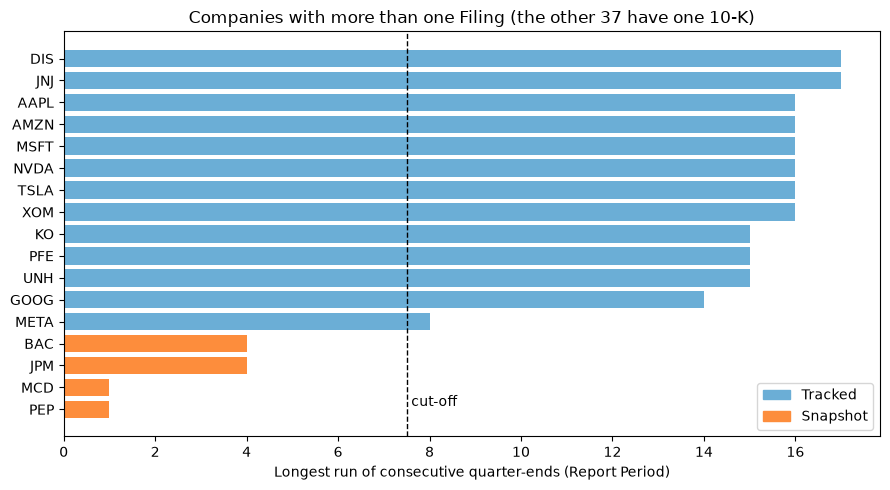

In [8]:
multi = coverage[coverage["filings"] > 1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    multi.index[::-1],
    multi["consecutive quarters"][::-1],
    color=["#6baed6" if c == "tracked" else "#fd8d3c" for c in multi["coverage"][::-1]],
)
ax.axvline(TRACKED_MIN_QUARTERS - 0.5, color="black", linestyle="--", linewidth=1)
ax.text(TRACKED_MIN_QUARTERS - 0.4, 0, "cut-off", va="bottom")
ax.set_xlabel("Longest run of consecutive quarter-ends (Report Period)")
ax.set_title("Companies with more than one Filing (the other 37 have one 10-K)")
ax.legend(
    handles=[Patch(color="#6baed6", label="Tracked"), Patch(color="#fd8d3c", label="Snapshot")],
    loc="lower right",
)
fig.tight_layout()
plt.show()

**Choosing the cut-off.** The runs fall into clear groups: 12 Companies cover 14–17
consecutive quarters from 2022 to 2025, META covers exactly 8 (2024Q1–2025Q4), BAC
and JPM cover 4, and MCD, PEP and the 37 single-10-K Companies never cover two
quarters in a row. Nothing falls between 4 and 8, so any cut-off from 5 to 8 gives
the same split. Eight is chosen because it is what the Client's own example asks for
("over the last two years") and what a year-over-year comparison of every quarter
needs.

**Borderline Companies:**

- **META (Tracked, 8 quarters):** exactly at the cut-off. Its Filings start in 2024,
  so "the last two years" is answerable but nothing earlier is.
- **BAC and JPM (Snapshot, 4 quarters):** one year of quarters (BAC 2024Q4–2025Q3,
  JPM 2025Q1–2025Q4). Quarter-on-quarter movement within that year is answerable, and
  each Filing carries prior-year comparatives, but a two-year trend is not.
- **MCD and PEP (Snapshot, 2 Filings each):** a 10-Q and a 10-K far apart (MCD
  2023Q1 and FY2024, PEP 2023Q1 and FY2025). Two point-in-time snapshots, not a trend.

### 1.3 Sectors

No Filing carries a Sector, so each Company is mapped to one from a curated
GICS-style reference table (`data/reference/sectors.csv`), which also holds the
Company's SEC SIC code and explains every case where the two disagree.

In [9]:
sectors = pd.DataFrame(load_sector_table()).set_index("ticker")
sector_summary = (
    pd.DataFrame(
        {
            "Companies": sectors.groupby("sector").size(),
            "Tracked": coverage.join(sectors)
            .query("coverage == 'tracked'")
            .groupby("sector")
            .size(),
            "Filings": pd.Series(Counter(f.sector for f in filings)),
        }
    )
    .fillna(0)
    .astype(int)
    .sort_values("Filings", ascending=False)
)
sector_summary["Companies (tickers)"] = sectors.groupby("sector").apply(
    lambda g: ", ".join(sorted(g.index))
)
sector_summary

,Companies,Tracked,Filings,Companies (tickers)
Information Technology,10,3,55,"AAPL, ADBE, AMD, CRM, CSCO, IBM, INTC, MSFT, N..."
Health Care,7,3,51,"ABBV, JNJ, LLY, MRK, PFE, TMO, UNH"
Communication Services,7,3,43,"CMCSA, DIS, GOOG, META, NFLX, T, VZ"
Consumer Discretionary,6,2,37,"AMZN, HD, MCD, NKE, SBUX, TSLA"
Consumer Staples,6,1,21,"COST, KO, PEP, PG, TGT, WMT"
Energy,2,1,17,"CVX, XOM"
Financials,10,0,16,"AXP, BAC, BLK, BRK, GE, GS, JPM, MA, MS, V"
Industrials,6,0,6,"BA, CAT, DE, LMT, RTX, UPS"


In [10]:
disagreements = sectors[~sectors["sic_agrees"]]
print(f"Companies whose SIC code points elsewhere than the GICS-style label: {len(disagreements)}")
with pd.option_context("display.max_colwidth", None):
    display(disagreements[["sector", "industry", "sic_code", "sic_description", "note"]])

Companies whose SIC code points elsewhere than the GICS-style label: 14


,sector,industry,sic_code,sic_description,note
ticker,,,,,
ABBV,Health Care,Biotechnology,2834,Pharmaceutical Preparations,"SIC files AbbVie with the other drug makers (2834); the GICS-style label puts it in Biotechnology. Same sector and same Pharmaceuticals, Biotechnology & Life Sciences group, so AbbVie counts as one of the major pharmaceutical companies alongside JNJ, LLY, MRK and PFE."
BRK,Financials,Financial Services,6331,"Fire, Marine & Casualty Insurance","SIC classes Berkshire by its insurance operations; the GICS-style label treats it as a multi-sector holding company (railroad, utilities, manufacturing and insurance). Same sector, different industry."
COST,Consumer Staples,Consumer Staples Distribution & Retail,5331,Retail-Variety Stores,"SIC has a single Retail division and no staples/discretionary split. The GICS-style label puts general merchandise retailers that mainly sell food and household goods (Costco, Target, Walmart) in Consumer Staples, apart from Amazon and Home Depot in Consumer Discretionary."
DIS,Communication Services,Entertainment,7990,Services-Miscellaneous Amusement & Recreation,"SIC reflects Disney's theme parks (amusement and recreation, a consumer services code); the GICS-style label classes it by its media and streaming business as Entertainment in Communication Services."
GOOG,Communication Services,Interactive Media & Services,7370,"Services-Computer Programming, Data Processing, Etc.",SIC classes Alphabet as a computer services company; the GICS-style label classes it by its advertising-funded search and YouTube business as Interactive Media & Services (moved from Information Technology to Communication Services in 2018).
IBM,Information Technology,IT Services,3570,Computer & office Equipment,"SIC still reflects IBM's hardware history; the GICS-style label classes it by today's software and consulting business as IT Services. Same sector, different industry."
MA,Financials,Financial Services,7389,"Services-Business Services, NEC","SIC classes payment networks as business services; the GICS-style label puts them in Financials (Transaction & Payment Processing Services), where GICS moved them from Information Technology in 2023."
META,Communication Services,Interactive Media & Services,7370,"Services-Computer Programming, Data Processing, Etc.",SIC classes Meta as a computer services company; the GICS-style label classes it by its advertising-funded social media business as Interactive Media & Services in Communication Services.
NFLX,Communication Services,Entertainment,7841,Services-Video Tape Rental,"SIC still files Netflix under video tape rental, from its DVD-by-mail origins; the GICS-style label classes the streaming business as Entertainment in Communication Services."


In [11]:
health_care = sectors[sectors["sector"] == "Health Care"].join(coverage["coverage"])
health_care[["company", "industry", "sic_code", "sic_description", "coverage"]]

,company,industry,sic_code,sic_description,coverage
ticker,,,,,
ABBV,AbbVie Inc,Biotechnology,2834,Pharmaceutical Preparations,snapshot
JNJ,Johnson & Johnson,Pharmaceuticals,2834,Pharmaceutical Preparations,tracked
LLY,Eli Lilly and Company,Pharmaceuticals,2834,Pharmaceutical Preparations,snapshot
MRK,Merck & Co Inc,Pharmaceuticals,2834,Pharmaceutical Preparations,snapshot
PFE,Pfizer Inc,Pharmaceuticals,2834,Pharmaceutical Preparations,tracked
TMO,Thermo Fisher Scientific Inc,Life Sciences Tools & Services,3829,"Measuring & Controlling Devices, NEC",snapshot
UNH,UnitedHealth Group Inc,Health Care Providers & Services,6324,Hospital & Medical Service Plans,tracked


**What the Sector table shows**

- The 54 Companies span eight GICS-style sectors; there is no Materials, Real Estate
  or Utilities Company. Filings are concentrated in Information Technology, Health
  Care and Communication Services because most Tracked Companies sit there. None of
  the 10 Financials Companies is Tracked: bank questions are point-in-time only.
- SIC and the GICS-style label disagree for 14 Companies, for five reasons: SIC
  codes are old (Netflix is "video tape rental", IBM "computer equipment"); SIC
  classifies by activity where GICS classifies by business model (Alphabet and Meta
  as computer services, Disney as amusement parks, UnitedHealth as an insurer, Thermo
  Fisher as an instrument maker); SIC has no staples/discretionary split for
  retailers (Walmart, Costco, Target); GICS has moved Companies since (Visa and
  Mastercard to Financials in 2023); and GICS draws finer industry lines inside the
  same sector (AbbVie as Biotechnology, Berkshire as a multi-sector holding company
  rather than an insurer).
- "The major pharmaceutical companies" resolves to five Companies: JNJ, LLY, MRK, PFE
  (GICS Pharmaceuticals) and ABBV (GICS Biotechnology). All five share SIC 2834.
  UnitedHealth and Thermo Fisher are Health Care but not drug makers, so they stay
  out. Only JNJ and PFE are Tracked; the other three have a single 10-K.
- The GE Filing is classed as Financials because it is GE Capital's report, even
  though the header names General Electric Company (today an Industrials Company).

**So the design does:**

- Carry Sector, industry and the Tracked/Snapshot class on every Filing and chunk.
  Sector-scoped questions filter on Sector or industry metadata, then retrieve per
  Company, instead of hoping similarity finds the right Companies.
- Resolve industry-group phrases with a small rule-based synonym list over the
  table (e.g. "pharmaceutical" → Pharmaceuticals and Biotechnology), keeping query
  parsing before the Answer Call rule-based.
- Tell the Answer Call each Company's coverage class, so a trend question about a
  Snapshot Company is answered as point-in-time with the limit stated, and a sector
  question says which Companies support trends.

## 2. Metadata integrity

Can every Filing be placed on the time axis and identified unambiguously? This
analysis checks the metadata from every angle available: the header, the file name,
the manifest, the source URL and the cover-page sentence ("For the fiscal year ended
..." / "For the quarterly period ended ...").

The Corpus seam resolves each Filing's Report Period from the header, else the date
in the source URL, else the cover-page sentence. It cross-checks every source that is
present and records disagreements as diagnostics on the Filing.

### 2.1 Manifest vs files on disk, and header vs file name

In [12]:
manifest = json.loads((DEFAULT_CORPUS_DIR / "manifest.json").read_text(encoding="utf-8"))
print("Manifest problems:", check_manifest() or "none")
print("Manifest Form Type counts:", manifest["filing_types"])
print("Header Form Type counts:  ", dict(Counter(f.form_type for f in filings)))

FILE_NAME = re.compile(r"^([A-Z]+)_(10K|10Q)_(?:(\d{4}Q[1-4])_)?(\d{4}-\d{2}-\d{2})_full\.txt$")
name_mismatches = []
for f in filings:
    ticker, form, quarter, filed = FILE_NAME.match(f.path.name).groups()
    expected = (f.ticker, f.form_type.replace("-", ""), f.calendar_quarter, str(f.filing_date))
    if (ticker, form, quarter, filed) != expected:
        name_mismatches.append(f.path.name)
print("File names disagreeing with their header (ticker, Form Type, Quarter, Filing Date):")
print("  ", name_mismatches or "none")

Manifest problems: none
Manifest Form Type counts: {'10-K': 89, '10-Q': 157}
Header Form Type counts:   {'10-K': 89, '10-Q': 157}
File names disagreeing with their header (ticker, Form Type, Quarter, Filing Date):
   none


### 2.2 Missing header fields and where each Report Period came from

In [13]:
header_fields = pd.DataFrame(
    {
        "Report Period in header": sum(f.report_period_source == "header" for f in filings),
        "Calendar Quarter in header": sum(f.calendar_quarter is not None for f in filings),
    },
    index=["Filings"],
)
header_fields["Filings in Corpus"] = len(filings)
header_fields

,Report Period in header,Calendar Quarter in header,Filings in Corpus
Filings,192,192,246


In [14]:
sources = pd.crosstab(
    pd.Series([f.report_period_source for f in filings], name="Report Period source"),
    pd.Series([f.form_type for f in filings], name="Form Type"),
    margins=True,
)
sources

Form Type,10-K,10-Q,All
Report Period source,,,
header,35,157,192
text,1,0,1
url,53,0,53
All,89,157,246


In [15]:
# Section diagnostics belong to analysis 4.
diagnostics = [
    (f.filing_id, d.code, d.detail)
    for f in filings
    for d in f.diagnostics
    if not d.code.startswith("section_")
]
print(f"Filings with a Report Period: {sum(f.report_period is not None for f in filings)}")
print(f"Diagnostics (source disagreements, missing cover-page sentence, ...): {len(diagnostics)}")
pd.DataFrame(diagnostics, columns=["filing_id", "code", "detail"])

Filings with a Report Period: 246
Diagnostics (source disagreements, missing cover-page sentence, ...): 0


,filing_id,code,detail


The 54 Filings with no Report Period in the header are exactly the 54 most recent
10-Ks, one per Company. 53 have a dated source URL; the cover-page sentence agrees
with it in every case. For the 192 Filings that do have a header Report Period, the
URL date and the cover-page sentence agree with it too. Two kinds of flattening
quirk had to be handled to find the sentence: the date glued to the phrase
(`endedDecember 31, 2025`) and a table cell between them
(`For the quarterly period ended | Commission file |\nMarch 31, 2025`).

### 2.3 The GE Filing

In [16]:
ge = next(f for f in filings if f.ticker == "GE")
ge_text = ge.path.read_text(encoding="utf-8")
registrant = re.search(r"([A-Z][A-Za-z ]+?)\s*\(Exact name of registrant", ge_text).group(1)
print(f"Header Company:      {ge.company} (CIK {ge.cik})")
print(f"Cover-page registrant: {registrant}")
print(f"Source URL:          {ge.source_url}")
print(f"Report Period:       {ge.report_period} (from {ge.report_period_source})")
print(f"Fiscal Period:       {ge.fiscal_period}, filed {ge.filing_date}")

Header Company:      General Electric Company (CIK 0000040554)
Cover-page registrant: General Electric Capital Corporation
Source URL:          https://www.sec.gov/Archives/edgar/data/40554/000004054515000032/gecc10k2014.htm
Report Period:       2014-12-31 (from text)
Fiscal Period:       FY2014, filed 2015-02-27


The GE Filing is **not** a General Electric Company report. Its header says "General
Electric Company", but the cover page names **General Electric Capital Corporation**
(GE Capital) as the registrant, the document is `gecc10k2014.htm`, and the CIK it is
filed under (0000040554) is GE Capital's EDGAR folder. It is GE Capital's 10-K for
the **fiscal year ended 31 December 2014**, filed on 27 February 2015. Its URL has no
date, so its Report Period comes from the cover-page sentence.

### 2.4 Calendar Quarter clashes

In [17]:
def calendar_quarter_of(d):
    return f"{d.year}Q{(d.month - 1) // 3 + 1}"


inconsistent = [
    f.filing_id
    for f in filings
    if f.calendar_quarter and f.calendar_quarter != calendar_quarter_of(f.report_period)
]
print("Calendar Quarter not the quarter its Report Period ends in:", inconsistent or "none")

by_cell = df.assign(filing=filings).dropna(subset=["calendar_quarter"])
clashes = pd.DataFrame(
    {
        "ticker": f.ticker,
        "calendar_quarter": f.calendar_quarter,
        "form_type": f.form_type,
        "report_period": f.report_period,
        "fiscal_period": f.fiscal_period,
        "filing_id": f.filing_id,
    }
    for _, group in by_cell.groupby(["ticker", "calendar_quarter"])
    if len(group) > 1
    for f in group["filing"]
)
clashes

Calendar Quarter not the quarter its Report Period ends in: none


,ticker,calendar_quarter,form_type,report_period,fiscal_period,filing_id
0,AAPL,2023Q3,10-K,2023-09-30,FY2023,AAPL_10-K_2023-09-30
1,AAPL,2023Q3,10-Q,2023-07-01,Q3 FY2023,AAPL_10-Q_2023-07-01
2,DIS,2022Q4,10-K,2022-10-01,FY2022,DIS_10-K_2022-10-01
3,DIS,2022Q4,10-Q,2022-12-31,Q1 FY2023,DIS_10-Q_2022-12-31
4,DIS,2023Q3,10-K,2023-09-30,FY2023,DIS_10-K_2023-09-30
5,DIS,2023Q3,10-Q,2023-07-01,Q3 FY2023,DIS_10-Q_2023-07-01
6,JNJ,2023Q4,10-K,2023-12-31,FY2023,JNJ_10-K_2023-12-31
7,JNJ,2023Q4,10-Q,2023-10-01,Q3 FY2023,JNJ_10-Q_2023-10-01
8,KO,2022Q3,10-Q,2022-07-01,Q2 FY2022,KO_10-Q_2022-07-01
9,KO,2022Q3,10-Q,2022-09-30,Q3 FY2022,KO_10-Q_2022-09-30


In [18]:
ids = [f.filing_id for f in filings]
cells = by_cell.groupby(["ticker", "calendar_quarter"]).ngroups
print(f"Company × Calendar Quarter cells with a Filing: {cells}")
print(f"Filings with a Calendar Quarter:                {len(by_cell)}")
print(f"Distinct Filing identifiers:                   {len(set(ids))} of {len(ids)}")

Company × Calendar Quarter cells with a Filing: 185
Filings with a Calendar Quarter:                192
Distinct Filing identifiers:                   246 of 246


Every Calendar Quarter label is correct by its own definition (the calendar quarter
in which the Report Period ends), yet seven Company × Calendar Quarter cells hold two
Filings. All seven come from 52/53-week fiscal calendars whose periods end a day or
two into the next calendar quarter. Coca-Cola's second quarter of 2022 ended on
1 July, so it shares 2022Q3 with its third quarter (30 September). Apple's and
Disney's third quarters of 2023 also ended on 1 July. Disney's FY2022 and Pfizer's
and J&J's third quarters ended on 1–2 October. The identifier
`ticker_FormType_ReportPeriod` keeps all 246 Filings distinct.

### 2.5 CIK and Company name consistency

In [19]:
ciks_per_ticker = df.assign(cik=[f.cik for f in filings]).groupby("ticker")["cik"].nunique()
tickers_per_cik = df.assign(cik=[f.cik for f in filings]).groupby("cik")["ticker"].nunique()
names_per_ticker = df.groupby("ticker")["company"].nunique()
url_not_under_cik = [f.filing_id for f in filings if f"/data/{int(f.cik)}/" not in f.source_url]
print(f"Tickers with more than one CIK:  {(ciks_per_ticker > 1).sum()}")
print(f"CIKs with more than one ticker:  {(tickers_per_cik > 1).sum()}")
print(f"Tickers with more than one name: {(names_per_ticker > 1).sum()}")
print(f"Filings whose URL is not under their CIK: {url_not_under_cik or 'none'}")

Tickers with more than one CIK:  0
CIKs with more than one ticker:  0
Tickers with more than one name: 0
Filings whose URL is not under their CIK: none


### 2.6 Fiscal year ends and Fiscal Periods

Each Company's fiscal year end is derived from its 10-K Report Periods. A period end
within the first seven days of a month counts as the end of the previous month, so
52/53-week years (Deere's 2 November, J&J's 2 January) map to the right month. Each
Filing's Fiscal Period is then counted from that month, and the fiscal year is named
after the calendar year in which it ends.

In [20]:
fiscal_year_ends = (
    pd.Series({f.ticker: f.fiscal_year_end_month for f in filings}, name="fiscal year end month")
    .map(lambda m: pd.Timestamp(2000, m, 1).strftime("%B"))
    .rename_axis("ticker")
)
fiscal_year_ends.value_counts().to_frame("Companies").T

fiscal year end month,December,January,September,June,May,November,August,July,October
Companies,37,5,4,2,2,1,1,1,1


In [21]:
fiscal_year_ends[fiscal_year_ends != "December"].to_frame().T

ticker,AAPL,ADBE,COST,CRM,CSCO,DE,DIS,HD,MSFT,NKE,NVDA,ORCL,PG,SBUX,TGT,V,WMT
fiscal year end month,September,November,August,January,July,October,September,January,June,May,January,May,June,September,January,September,January


In [22]:
example = next(f for f in filings if f.ticker == "NVDA" and str(f.report_period) == "2025-07-27")
print(f"{example.filing_id}: {example.fiscal_period}")
print(f"Filings without a Fiscal Period: {sum(f.fiscal_period is None for f in filings)}")

NVDA_10-Q_2025-07-27: Q2 FY2026
Filings without a Fiscal Period: 0


17 of 54 Companies do not have a December year end. The Fiscal Period rule reproduces
each Company's own label where we checked it (NVIDIA's quarter ending 27 July 2025 is
Q2 FY2026; Apple, Microsoft, Walmart and Salesforce match their reports). It does
**not** match retailers that name a fiscal year after the year it starts in: Home
Depot calls the year ended 2 February 2025 "fiscal 2024", and Target likewise, while
the rule labels it FY2025. Both are Snapshot Companies with one 10-K each, and the
Fiscal Period is a secondary label, so this is recorded rather than special-cased.

### 2.7 Filings outside the brief's "2023–2025" window

In [23]:
out_of_window = sorted(
    (f for f in filings if not 2023 <= f.report_period.year <= 2025),
    key=lambda f: (f.report_period, f.ticker),
)
print(f"Filings with a Report Period outside 2023–2025: {len(out_of_window)}")
pd.DataFrame(
    {
        "ticker": f.ticker,
        "form_type": f.form_type,
        "report_period": f.report_period,
        "fiscal_period": f.fiscal_period,
        "filing_date": f.filing_date,
    }
    for f in out_of_window
).groupby("ticker").agg(
    filings=("form_type", "size"),
    first=("report_period", "min"),
    last=("report_period", "max"),
    forms=("form_type", lambda s: ", ".join(f"{n} {t}" for t, n in Counter(s).items())),
)

Filings with a Report Period outside 2023–2025: 48


,filings,first,last,forms
ticker,,,,
AAPL,4,2022-03-26,2022-12-31,"3 10-Q, 1 10-K"
AMZN,4,2022-03-31,2022-12-31,"3 10-Q, 1 10-K"
DIS,5,2022-01-01,2022-12-31,"4 10-Q, 1 10-K"
GE,1,2014-12-31,2014-12-31,1 10-K
GOOG,2,2022-09-30,2022-12-31,"1 10-Q, 1 10-K"
JNJ,4,2022-01-02,2022-10-02,"1 10-K, 3 10-Q"
KO,4,2022-04-01,2022-12-31,"3 10-Q, 1 10-K"
MSFT,4,2022-03-31,2022-12-31,"3 10-Q, 1 10-K"
NVDA,4,2022-01-30,2022-10-30,"1 10-K, 3 10-Q"


In [24]:
filed_after = [f for f in filings if f.filing_date.year > 2025]
print(f"Filings inside the window by Report Period but filed in 2026: {len(filed_after)}")
print("By Form Type:", dict(Counter(f.form_type for f in filed_after)))

Filings inside the window by Report Period but filed in 2026: 27
By Form Type: {'10-Q': 3, '10-K': 24}


**What the integrity checks show**

- The metadata is internally consistent: the manifest matches the files on disk, every
  file name agrees with its header, each ticker has one CIK and one name, and every
  source URL sits under the Filing's CIK.
- Every Filing now has a Report Period: 192 from the header, 53 from the source URL
  and 1 (GE Capital) from the cover-page sentence. Where more than one source exists
  they agree, so there are no diagnostics to review by hand.
- The "GE" Filing is GE Capital's FY2014 10-K, filed in 2015, under GE's ticker.
- Seven Company × Calendar Quarter cells hold two Filings, all caused by 52/53-week
  fiscal calendars. The identifier `ticker_FormType_ReportPeriod` is unique.
- 17 Companies have a non-December fiscal year end.
- 48 Filings have a Report Period outside 2023–2025: GE Capital's FY2014 10-K and 47
  Filings from 12 Companies in 2022 (including J&J's FY2021 10-K, whose year
  ended 2 January 2022). A further 27 Filings fall inside the window but were filed
  in 2026: 24 FY2025 10-Ks and 3 10-Qs for quarters ending in December 2025.

**So the design does:**

- Use the Report Period as the time axis and `ticker_FormType_ReportPeriod` as the
  Filing key everywhere (chunk metadata, citations, Financial Facts). Never key on
  Calendar Quarter or Filing Date.
- Keep the Report Period source on every Filing and keep cross-checking it, so a new
  Filing whose sources disagree is surfaced, not silently trusted.
- Show both the Report Period and the Fiscal Period in citations ("NVIDIA 10-Q, Q2
  FY2026, period ended 2025-07-27"), and resolve relative questions ("last two
  years", "latest") on Report Period.
- Keep all 48 out-of-window Filings, but flag GE Capital's FY2014 10-K as stale and
  attribute it to GE Capital, not General Electric, in any answer that uses it.

## 3. Text anatomy

What is each Filing actually made of? Every character of the raw body (the text
after the header) is put in one of five classes:

- **XBRL noise**: the machine-readable residue in front of the cover page, which the
  Corpus seam removes (`Filing.xbrl_noise_chars`).
- **TOC**: the table of contents the seam locates (`Filing.toc`).
- **Exhibits and signatures**: exhibit-index rows ("31.1 | Certification of ...") and
  signature lines ("/s/ ...", "SIGNATURES", "duly caused this report to be signed").
- **Flattened tables**: any other line made of `|`-separated cells, the remains of
  HTML tables. A line counts only if none of its cells is longer than 500
  characters: some Filings glue whole pages of prose into one line around a page
  footer such as "Apple Inc. | 2024 Form 10-K | 20", and that prose is not a table.
- **Prose**: everything else.

The last three are line-level heuristics written for this analysis, not part of the
core package; they are good enough to size cleaning priorities, not to cut text.

In [25]:
EXHIBIT_ROW = re.compile(
    r"^\s*\|?\s*(?:\d{1,3}(?:\.[0-9A-Z]{1,4}){1,2}|10[14])\s*[*†‡#+^]*\s*(?:\(\w\))?\s*\|"
)
SIGNATURE_LINE = re.compile(
    r"/s/|^\s*SIGNATURES?\s*$|duly caused this report to be signed", re.IGNORECASE
)
RUNNING_HEADER = re.compile(r"Table of Contents", re.IGNORECASE)
MAX_TABLE_CELL = 500
CLASSES = ["XBRL noise", "TOC", "Exhibits and signatures", "Flattened tables", "Prose"]


def anatomy(filing):
    """Characters of the raw body in each class."""
    chars = dict.fromkeys(CLASSES, 0)
    chars["XBRL noise"] = filing.xbrl_noise_chars
    toc_start, toc_end = (filing.toc.start, filing.toc.end) if filing.toc else (0, 0)
    pos = 0
    for line in filing.body.split("\n"):
        size = len(line) + 1
        if toc_start <= pos < toc_end:
            chars["TOC"] += size
        elif EXHIBIT_ROW.match(line) or SIGNATURE_LINE.search(line):
            chars["Exhibits and signatures"] += size
        elif "|" in line and max(len(cell) for cell in line.split("|")) <= MAX_TABLE_CELL:
            chars["Flattened tables"] += size
        else:
            chars["Prose"] += size
        pos += size
    return chars


def running_headers(filing):
    """'Table of Contents' page headers left in the text outside the TOC itself."""
    toc_text = filing.body[filing.toc.start : filing.toc.end] if filing.toc else ""
    return len(RUNNING_HEADER.findall(filing.body)) - len(RUNNING_HEADER.findall(toc_text))


anat = pd.DataFrame(
    {
        "ticker": f.ticker,
        "form_type": f.form_type,
        "file": f.path.name,
        "raw_chars": f.xbrl_noise_chars + len(f.body),
        "has_toc": f.toc is not None,
        "running_headers": running_headers(f),
        "longest_line": max(len(line) for line in f.body.split("\n")),
        **anatomy(f),
    }
    for f in filings
)
assert (anat[CLASSES].sum(axis=1) == anat["raw_chars"] + 1).all()  # +1: the final newline


def shares(frame):
    """Character-weighted share of each class, in percent."""
    return (frame[CLASSES].sum() / frame[CLASSES].sum().sum() * 100).round(1)


by_form = pd.DataFrame(
    {
        "Corpus": shares(anat),
        "10-K": shares(anat[anat["form_type"] == "10-K"]),
        "10-Q": shares(anat[anat["form_type"] == "10-Q"]),
    }
).T
by_form

,XBRL noise,TOC,Exhibits and signatures,Flattened tables,Prose
Corpus,13.6,0.4,2.6,19.7,63.7
10-K,11.6,0.3,3.8,16.5,67.7
10-Q,16.2,0.5,1.1,23.5,58.7


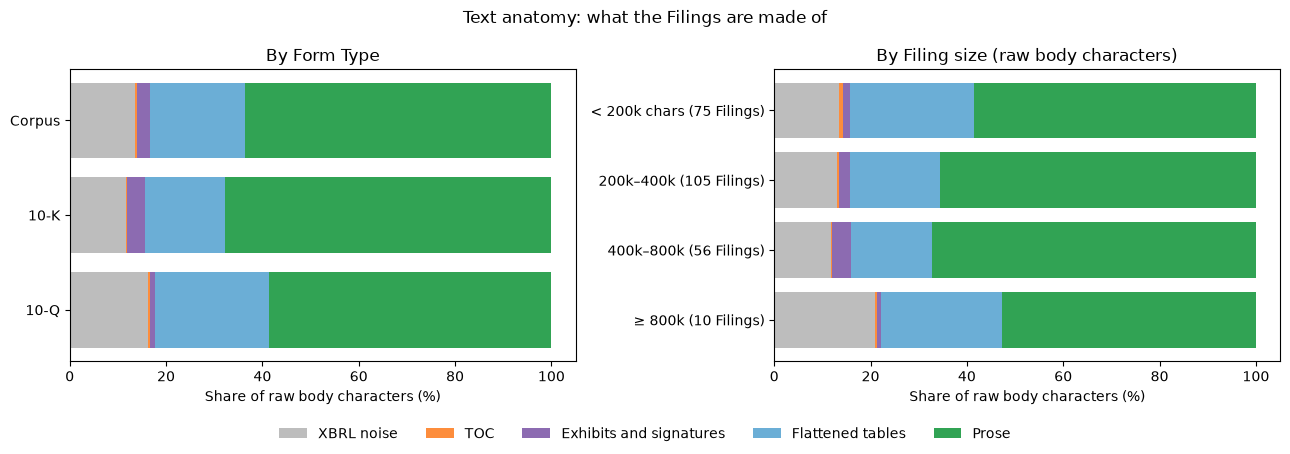

,XBRL noise,TOC,Exhibits and signatures,Flattened tables,Prose,Filings
size_bin,,,,,,
< 200k chars,13.5,0.7,1.4,25.7,58.6,75
200k–400k,13.1,0.4,2.2,18.7,65.6,105
400k–800k,11.7,0.3,4.0,16.7,67.2,56
≥ 800k,21.0,0.3,0.8,25.2,52.7,10


In [26]:
size_bins = [0, 200_000, 400_000, 800_000, float("inf")]
size_labels = ["< 200k chars", "200k–400k", "400k–800k", "≥ 800k"]
anat["size_bin"] = pd.cut(anat["raw_chars"], size_bins, labels=size_labels, right=False)
by_size = anat.groupby("size_bin", observed=True)[CLASSES].sum()
by_size = by_size.div(by_size.sum(axis=1), axis=0) * 100
filings_per_bin = anat["size_bin"].value_counts().reindex(size_labels)

class_colours = ["#bdbdbd", "#fd8d3c", "#8c6bb1", "#6baed6", "#31a354"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, frame, title, ylabels in [
    (ax1, by_form, "By Form Type", by_form.index),
    (
        ax2,
        by_size,
        "By Filing size (raw body characters)",
        [f"{b} ({filings_per_bin[b]} Filings)" for b in by_size.index],
    ),
]:
    left = np.zeros(len(frame))
    for cls, colour in zip(CLASSES, class_colours, strict=True):
        ax.barh(range(len(frame)), frame[cls], left=left, color=colour, label=cls)
        left += frame[cls].to_numpy()
    ax.set_yticks(range(len(frame)), ylabels)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Share of raw body characters (%)")
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False)
fig.suptitle("Text anatomy: what the Filings are made of")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

by_size.round(1).assign(Filings=filings_per_bin)

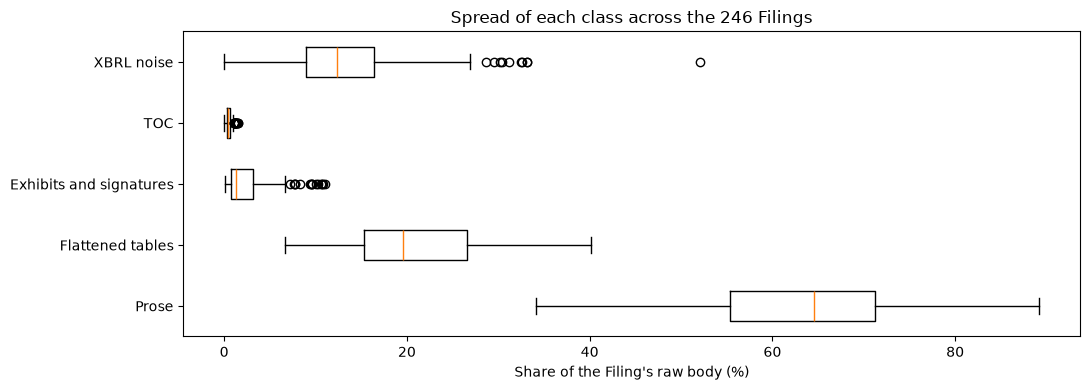

,file,raw_chars,XBRL noise %,TOC %,Exhibits and signatures %,Flattened tables %,Prose %
84,IBM_10K_2025-02-25_full.txt,222965,52.1,0.6,1.2,12.0,34.1
38,BAC_10Q_2025Q2_2025-07-31_full.txt,831442,33.1,0.3,0.3,31.9,34.3
39,BAC_10Q_2025Q3_2025-10-31_full.txt,833401,33.1,0.3,0.3,32.0,34.3
101,JNJ_10Q_2025Q2_2025-07-24_full.txt,305834,32.6,0.4,0.4,20.0,46.6
102,JNJ_10Q_2025Q3_2025-10-22_full.txt,311308,32.5,0.4,0.3,20.0,46.8
37,BAC_10Q_2025Q1_2025-04-30_full.txt,715232,31.2,0.4,0.5,31.4,36.6
98,JNJ_10Q_2024Q2_2024-07-25_full.txt,312509,30.4,0.4,0.4,21.2,47.7
99,JNJ_10Q_2024Q3_2024-10-23_full.txt,316057,30.2,0.4,0.4,19.9,49.1


In [27]:
per_filing = anat.assign(
    **{f"{c} %": (anat[c] / anat["raw_chars"] * 100).round(1) for c in CLASSES}
)
pct = [f"{c} %" for c in CLASSES]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([per_filing[c] for c in pct], orientation="horizontal", tick_labels=CLASSES)
ax.invert_yaxis()
ax.set_xlabel("Share of the Filing's raw body (%)")
ax.set_title("Spread of each class across the 246 Filings")
fig.tight_layout()
plt.show()

per_filing.sort_values("XBRL noise %", ascending=False)[["file", "raw_chars", *pct]].head(8)

In [28]:
print(f"XBRL noise removed: {anat['XBRL noise'].sum() / 1e6:.1f}M characters in total")
print(
    "Filings where XBRL noise is over 20% of the raw body: "
    f"{(per_filing['XBRL noise %'] > 20).sum()}"
)
print(f"Filings without a table of contents: {(~anat['has_toc']).sum()}")
print(", ".join(anat.loc[~anat["has_toc"], "file"]))
print(
    "Filings with 'Table of Contents' running page headers left in the text: "
    f"{(anat['running_headers'] > 0).sum()} "
    f"({anat['running_headers'].sum()} headers in total)"
)
print(
    "Filings with a single line over 20,000 characters: "
    f"{(anat['longest_line'] > 20_000).sum()} "
    f"(longest: {anat['longest_line'].max():,} characters, "
    f"{anat.loc[anat['longest_line'].idxmax(), 'file']})"
)

XBRL noise removed: 11.1M characters in total
Filings where XBRL noise is over 20% of the raw body: 31
Filings without a table of contents: 9
DIS_10Q_2022Q1_2022-02-09_full.txt, DIS_10Q_2022Q2_2022-05-11_full.txt, DIS_10Q_2022Q3_2022-08-10_full.txt, DIS_10Q_2022Q4_2023-02-08_full.txt, DIS_10Q_2023Q2_2023-05-10_full.txt, DIS_10Q_2023Q3_2023-08-09_full.txt, DIS_10Q_2023Q4_2024-02-07_full.txt, DIS_10Q_2024Q1_2024-05-07_full.txt, DIS_10Q_2024Q2_2024-08-07_full.txt
Filings with 'Table of Contents' running page headers left in the text: 204 (7813 headers in total)
Filings with a single line over 20,000 characters: 135 (longest: 287,855 characters, META_10K_2024Q4_2025-01-30_full.txt)


**What the anatomy shows**

- XBRL noise is 13.6% of all raw text (11.1M characters), more in 10-Qs (16%) than
  10-Ks (12%), over 20% in 31 Filings and 52% in IBM's 10-K. It is pure machine
  residue (context IDs, taxonomy URLs, hidden facts) glued in front of the cover
  page. The Corpus seam strips it, and a Corpus-level test checks that no cleaned
  body contains an XBRL signature.
- Flattened tables are about a fifth of the text (24% in 10-Qs, a quarter of the
  largest Filings). They hold most of the numbers the Client will ask about, but as
  rows of `|`-separated cells, so a value cut away from its row and column labels
  means nothing.
- The TOC is small (under 1%) but dangerous: its rows repeat every Item heading.
  The seam locates it in all but nine Filings (Disney 10-Qs before 2025, which have
  none), always in the first tenth of the body.
- Exhibit indexes and signatures are about 3% (4% of 10-Ks) and carry no business
  content.
- Line breaks are not paragraph breaks. 135 Filings have a single line over 20,000
  characters (META's longest is 287,855): whole pages of prose glued together, with
  page footers ("Apple Inc. | 2024 Form 10-K | 20") and "Table of Contents" running
  headers (7,813 of them, in 204 Filings) embedded mid-line.

**So the design does:**

- Index only the cleaned body: XBRL noise never reaches a chunk or a prompt.
- Skip the TOC span in Section detection (next analysis) and leave it out of the
  index, so a TOC row like "Item 1A. | Risk Factors | 5" is never retrieved as if it
  were the Risk Factors.
- Leave exhibit indexes and signatures out of the index.
- Chunk tables as whole tables (or row groups that repeat the table's header rows),
  never splitting a row from its labels, and tag them as table chunks so the Answer
  Call knows it is reading a table. Their numbers are also the input to the Financial
  Facts experiment (analysis 7).
- Split prose on sentence boundaries within a token budget, not on line breaks, and
  strip running page headers and page footers before chunking so they do not pollute
  chunk text and embeddings.

## 4. Section and Item detection

Can Filings be addressed by Section? The Corpus seam splits each cleaned body at its
Item headings, skipping the TOC. Each Section carries a standard, form-independent
name and the Item label the Filing used, so 10-K Item 7 and 10-Q Part I, Item 2 are
both **MD&A**, while a question about "Item 7" can still filter on the label. Text
before the first heading (cover page, TOC, forward-looking statements) is kept as
an **Unsectioned** Section, so the Sections of a Filing add up to its whole body.

A heading is an Item number followed by the start of the Item's official title
("Item 1A. Risk Factors"). Flattening glues headings into running text, so the
splitter cannot rely on line starts. It rejects three look-alikes:

- **cross-references**, which cite an Item mid-sentence ("see Part II, Item 7,
  “Management's Discussion…”"): a heading is never preceded by a lower-case word, a
  comma or an opening quote, unless that word ends a "Table of Contents" page header;
- **TOC rows**, by searching only after the TOC;
- **cross-reference index rows** near the end of some 10-Ks ("Item 1A | Risk Factors |
  Page28"): runs of five or more short table rows naming Items.

Items are searched for in form order first, then any still missing anywhere after
the TOC, because some Filings reorder them. A required Section that cannot be found
is recorded as a `section_not_found` diagnostic on the Filing.

In [29]:
section_rows = pd.DataFrame(
    {
        "file": f.path.name,
        "ticker": f.ticker,
        "form_type": f.form_type,
        "section": s.name,
        "item": s.item,
        "chars": len(s.text),
        "share": len(s.text) / len(f.body),
    }
    for f in filings
    for s in f.sections
)
items = section_rows.dropna(subset=["item"])
mapping = (
    items.groupby(["form_type", "item", "section"], sort=False)
    .size()
    .rename("Filings")
    .reset_index()
)
mapping["order"] = (
    mapping["item"]
    .str.extract(r"(\d+)([A-C]?)$")
    .apply(lambda m: int(m[0]) * 10 + (ord(m[1]) - 64 if m[1] else 0), axis=1)
    + mapping["item"].str.startswith("Part II").astype(int) * 1000
)
mapping.sort_values(["form_type", "order"]).drop(columns="order").set_index(["form_type", "item"])

section  Filings
form_type item                                              
10-K      Item 1                           Business       86
          Item 1A                      Risk Factors       86
          Item 1B                             Other       82
          Item 1C                     Cybersecurity       69
          Item 2                              Other       84
          Item 3                  Legal Proceedings       86
          Item 4                              Other       82
          Item 5                              Other       85
          Item 6                              Other       78
          Item 7                               MD&A       85
          Item 7A                       Market Risk       86
          Item 8               Financial Statements       85
          Item 9                              Other       85
          Item 9A           Controls and Procedures       86
          Item 9B                             Other       85
          Item 9C                             Other       82
          Item 10                             Other       83
          Item 11                             Other       83
          Item 12                             Other       83
          Item 13                             Other       83
          Item 14                             Other       85
          Item 15                             Other       86
          Item 16                             Other       79
10-Q      Part I, Item 1       Financial Statements      154
          Part I, Item 2                       MD&A      154
          Part I, Item 3                Market Risk      157
          Part I, Item 4    Controls and Procedures      157
          Part II, Item 1         Legal Proceedings      157
          Part II, Item 1A             Risk Factors      133
          Part II, Item 2                     Other      144
          Part II, Item 3                     Other       39
          Part II, Item 4                     Other       39
          Part II, Item 5                     Other      112
          Part II, Item 6                     Other      157

In [30]:
REQUIRED = {
    "10-K": [
        "Business",
        "Risk Factors",
        "Legal Proceedings",
        "MD&A",
        "Market Risk",
        "Financial Statements",
        "Controls and Procedures",
        "Cybersecurity",
    ],
    "10-Q": [
        "Financial Statements",
        "MD&A",
        "Market Risk",
        "Controls and Procedures",
        "Legal Proceedings",
        "Risk Factors",
    ],
}
found = items.groupby(["form_type", "section"])["file"].nunique()
filings_per_form = Counter(f.form_type for f in filings)
detection = pd.DataFrame(
    {
        form: {
            name: f"{found.get((form, name), 0)}/{filings_per_form[form]} "
            f"({found.get((form, name), 0) / filings_per_form[form]:.0%})"
            for name in REQUIRED[form]
        }
        for form in ["10-K", "10-Q"]
    }
).fillna("–")
detection

,10-K,10-Q
Business,86/89 (97%),–
Risk Factors,86/89 (97%),133/157 (85%)
Legal Proceedings,86/89 (97%),157/157 (100%)
MD&A,85/89 (96%),154/157 (98%)
Market Risk,86/89 (97%),157/157 (100%)
Financial Statements,85/89 (96%),154/157 (98%)
Controls and Procedures,86/89 (97%),157/157 (100%)
Cybersecurity,69/89 (78%),–


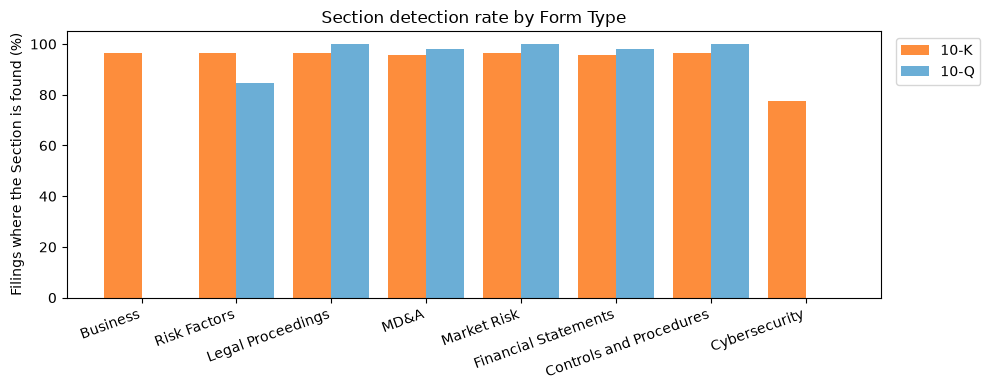

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
names = REQUIRED["10-K"]
x = np.arange(len(names))
for offset, form, colour in [(-0.2, "10-K", "#fd8d3c"), (0.2, "10-Q", "#6baed6")]:
    rates = [
        found.get((form, n), 0) / filings_per_form[form] * 100 if n in REQUIRED[form] else 0
        for n in names
    ]
    ax.bar(x + offset, rates, width=0.4, color=colour, label=form)
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set_ylabel("Filings where the Section is found (%)")
ax.set_ylim(0, 105)
ax.set_title("Section detection rate by Form Type")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

### 4.1 Every failure, by name

In [32]:
failures = pd.DataFrame(
    {"file": f.path.name, "form_type": f.form_type, "missing": d.detail}
    for f in filings
    for d in f.diagnostics
    if d.code == "section_not_found"
)
print(f"section_not_found diagnostics: {len(failures)} in {failures['file'].nunique()} Filings")
failures.groupby(["file", "form_type"])["missing"].agg("; ".join).to_frame()

section_not_found diagnostics: 53 in 32 Filings


,,missing
file,form_type,
BAC_10K_2025-02-25_full.txt,10-K,MD&A (Item 7)
CMCSA_10K_2026-02-03_full.txt,10-K,Financial Statements (Item 8)
INTC_10K_2026-01-23_full.txt,10-K,Business (Item 1); Risk Factors (Item 1A); Leg...
JNJ_10Q_2022Q2_2022-04-29_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2022Q3_2022-07-29_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2022Q4_2022-10-27_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q2_2023-04-28_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q3_2023-07-31_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q4_2023-10-27_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"


Reading each failing Filing shows why:

- **Morgan Stanley, Intel, McDonald's (10-K):** no "Item N" headings in the body at
  all. They use their own headings, mapped to Items in the TOC (Morgan Stanley) or in
  a cross-reference index at the end (Intel, McDonald's). The whole body after the
  TOC is Unsectioned.
- **JPMorgan (10-Q × 3):** the same pattern in its 10-Qs: MD&A and the financial
  statements run under JPMorgan's own headings; only Part II has Item headings.
- **Bank of America (10-K) and Comcast (10-K):** the Company name sits between the
  label and the title ("Item 7. Bank of America Corporation and Subsidiaries /
  Management's Discussion…", "Item 8: Comcast Corporation Financial Statements…").
  Their MD&A and financial statements stay inside the previous Item.
- **J&J and ExxonMobil (10-Q × 24):** not a detection failure. Their 10-Qs have no
  Part II, Item 1A at all; both rely on the risk factors in their 10-K.

Cybersecurity (Item 1C) only became required for fiscal years ending on or after
15 December 2023, so its absence from earlier 10-Ks is not reported as a failure.

### 4.2 Section lengths, stubs and coverage

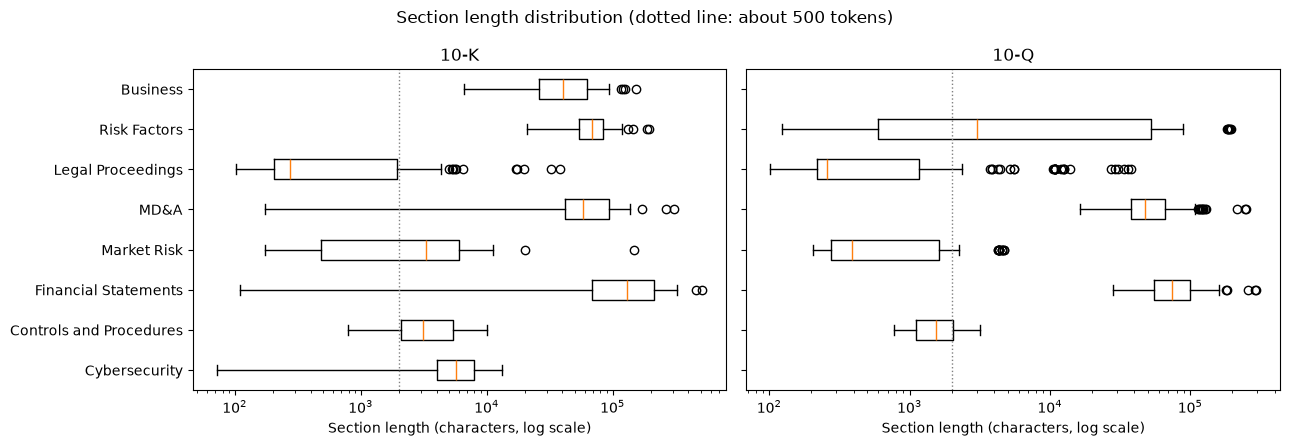

count    min    10%     50%     90%     max
form_type section                                                             
10-K      Business                    86   6638  13558   40290   82224  153071
          Controls and Procedures     86    793   1418    3106    7827    9985
          Cybersecurity               69     72   3291    5719    9132   13199
          Financial Statements        85    111    206  130948  255968  513246
          Legal Proceedings           86    102    159     276    5335   38463
          MD&A                        85    175  16263   57995  126726  307569
          Market Risk                 86    173    295    3288    7533  146561
          Risk Factors                86  20981  37922   69147  108594  195330
10-Q      Controls and Procedures    157    780   1020    1532    2255    3189
          Financial Statements       154  28206  36671   73699  144233  292973
          Legal Proceedings          157    102    135     260   10771   37854
          MD&A                       154  16298  29692   47565  106621  248043
          Market Risk                157    204    227     391    2076    4699
          Risk Factors               133    123    388    3015   72126  194389

In [33]:
named = items[items["section"] != "Other"]
order = REQUIRED["10-K"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, form in zip(axes, ["10-K", "10-Q"], strict=True):
    present = [n for n in order if n in REQUIRED[form]]
    data = [named[(named["form_type"] == form) & (named["section"] == n)]["chars"] for n in present]
    ax.boxplot(data, positions=[order.index(n) for n in present], orientation="horizontal")
    ax.set_xscale("log")
    ax.axvline(2_000, color="grey", linestyle=":", linewidth=1)
    ax.set_title(form)
    ax.set_xlabel("Section length (characters, log scale)")
axes[0].set_yticks(range(len(order)), order)
axes[0].invert_yaxis()
fig.suptitle("Section length distribution (dotted line: about 500 tokens)")
fig.tight_layout()
plt.show()

named.groupby(["form_type", "section"])["chars"].describe(percentiles=[0.1, 0.5, 0.9]).astype(int)[
    ["count", "min", "10%", "50%", "90%", "max"]
]

In [34]:
POINTER = re.compile(
    r"refer to|see |incorporated (?:herein )?by reference|no material changes|"
    r"is (?:included|presented|set forth) (?:in|under)|not applicable|^\W*none",
    re.IGNORECASE,
)
STUB_CHARS = 1_000
stub_rows = named[named["chars"] < STUB_CHARS].copy()
texts = {(f.path.name, s.item): s.text for f in filings for s in f.sections if s.item is not None}
stub_rows["points_elsewhere"] = [
    bool(POINTER.search(texts[(r.file, r.item)])) for r in stub_rows.itertuples()
]
stubs = (
    stub_rows.groupby(["form_type", "section"])
    .agg(stubs=("file", "size"), pointing_elsewhere=("points_elsewhere", "sum"))
    .join(named.groupby(["form_type", "section"]).size().rename("found"))
)
stubs["stub share"] = (stubs["stubs"] / stubs["found"] * 100).round(0).astype(int).astype(str) + "%"
stubs

stubs  pointing_elsewhere  found stub share
form_type section                                                             
10-K      Controls and Procedures      2                   1     86         2%
          Cybersecurity                4                   4     69         6%
          Financial Statements        20                  19     85        24%
          Legal Proceedings           56                  54     86        65%
          MD&A                         8                   3     85         9%
          Market Risk                 26                  18     86        30%
10-Q      Controls and Procedures     12                   0    157         8%
          Legal Proceedings          113                 101    157        72%
          Market Risk                104                  82    157        66%
          Risk Factors                52                  31    133        39%

In [35]:
for file, item in [
    ("JPM_10K_2026-02-13_full.txt", "Item 7"),
    ("AMZN_10K_2024Q4_2025-02-07_full.txt", "Item 3"),
    ("DIS_10K_2025-11-13_full.txt", "Item 8"),
    ("KO_10Q_2025Q1_2025-05-01_full.txt", "Part I, Item 3"),
]:
    print(f"{file} {item}:\n  {texts[(file, item)][:260]!r}\n")

JPM_10K_2026-02-13_full.txt Item 7:
  'Item 7. Management’s Discussion and Analysis of Financial Condition and Results of Operations.Management’s discussion and analysis of financial condition and results of operations, entitled “Management’s discussion and analysis,” appears on pages 46–160. Such '

AMZN_10K_2024Q4_2025-02-07_full.txt Item 3:
  'Item\xa03. | Legal Proceedings\nSee Item\xa08 of Part II, “Financial Statements and Supplementary Data — Note 7 — Commitments and Contingencies — Legal Proceedings.”\n'

DIS_10K_2025-11-13_full.txt Item 8:
  'ITEM\xa08. Financial Statements and Supplementary DataSee Index to Financial Statements and Supplemental Data on page 67.'

KO_10Q_2025Q1_2025-05-01_full.txt Part I, Item 3:
  'Item\xa03.\xa0Quantitative and Qualitative Disclosures About Market RiskWe have no material changes to the disclosures on this matter made in our Annual Report on Form\xa010-K for the year ended December\xa031, 2024.'



In [36]:
coverage = section_rows.assign(
    kind=np.where(section_rows["section"] == UNSECTIONED, "Unsectioned", "Item Sections")
)
by_kind = coverage.groupby(["form_type", "kind"])["chars"].sum().unstack()
(by_kind.div(by_kind.sum(axis=1), axis=0) * 100).round(1)

kind,Item Sections,Unsectioned
form_type,,
10-K,93.6,6.4
10-Q,89.5,10.5


In [37]:
unsectioned_share = (
    coverage[coverage["kind"] == "Unsectioned"].groupby("file")["share"].sum().sort_values()
)
print("Filings where more than 10% of the body is Unsectioned:")
print((unsectioned_share[unsectioned_share > 0.10] * 100).round(1).to_string())

last_items = section_rows.dropna(subset=["item"]).groupby("file").tail(1)
swallowing = last_items[last_items["share"] > 0.25].sort_values("share", ascending=False)
print("\nFilings whose last Item runs over a quarter of the body (trailing material):")
print(
    swallowing.assign(share=(swallowing["share"] * 100).round(1))[
        ["file", "item", "chars", "share"]
    ].to_string(index=False)
)

Filings where more than 10% of the body is Unsectioned:
file
JPM_10Q_2025Q3_2025-11-04_full.txt     98.3
JPM_10Q_2025Q1_2025-05-01_full.txt     98.5
JPM_10Q_2025Q2_2025-08-05_full.txt     98.7
INTC_10K_2026-01-23_full.txt          100.0
MCD_10K_2025-02-25_full.txt           100.0
MS_10K_2026-02-19_full.txt            100.0

Filings whose last Item runs over a quarter of the body (trailing material):
                              file    item   chars  share
       JPM_10K_2026-02-13_full.txt Item 15 1098530   86.0
       XOM_10K_2026-02-18_full.txt Item 16  352098   76.1
XOM_10K_2024Q4_2025-02-19_full.txt Item 16  375499   74.8
XOM_10K_2023Q4_2024-02-28_full.txt Item 16  354212   74.1
XOM_10K_2022Q4_2023-02-22_full.txt Item 16  347299   73.9
        DE_10K_2025-12-18_full.txt Item 16  309614   68.8
      NFLX_10K_2026-01-23_full.txt Item 15  125417   43.4
DIS_10K_2024Q3_2024-11-14_full.txt Item 16  195372   41.4
       DIS_10K_2025-11-13_full.txt Item 16  190131   40.8
DIS_10K_2022Q4_20

**What Section detection shows**

- Item headings are found in 96–97% of 10-Ks for every required Section and in
  98–100% of 10-Qs, apart from 10-Q Risk Factors (85%), where all 24 misses are J&J
  and ExxonMobil 10-Qs that have no Part II, Item 1A. The 53 `section_not_found`
  diagnostics sit in 32 Filings. Excluding those genuine absences, detection fails in
  eight Filings: Morgan Stanley, Intel and McDonald's 10-Ks and JPMorgan's three
  10-Qs, which use their own headings, and Bank of America's and Comcast's 10-Ks,
  which put the Company name inside the heading.
- TOC rows never become Section starts, and the cross-reference index rows at the end
  of Intel's, McDonald's and Mastercard's 10-Ks are rejected too. Bank of America's
  10-Qs, which open with MD&A and put the financial statements after Items 3 and 4,
  are split correctly.
- The Sections plus the Unsectioned text add up to every cleaned body. Unsectioned
  text is 6% of 10-K text and 10% of 10-Q text: mostly cover pages and TOCs, plus
  the whole body of the six Filings without Item headings.
- **An Item label says where content belongs, not always where it is.** Many
  Sections are stubs that point elsewhere. Legal Proceedings is under 1,000 characters
  in 65% of 10-Ks and 72% of 10-Qs ("See Note 7 — Commitments and Contingencies"),
  10-Q Market Risk in 66% ("no material changes"), 10-Q Risk Factors in 39%, and
  10-K Financial Statements in 24% ("See Index to Financial Statements on page 67").
  Where the content really is, it often follows the last Item. JPMorgan's Item 7 says
  its MD&A "appears on pages 46–160" of the Annual Report appended after Item 15,
  which makes Item 15 86% of the body. ExxonMobil's financial section follows Item 16
  (74–76% of each of its 10-Ks), and Deere's, Netflix's, Disney's and BlackRock's
  financial statements do the same (31–69%).
- Section sizes vary by two orders of magnitude. 10-K Risk Factors has a median of
  69,000 characters, MD&A 58,000 and Business 40,000; Controls and Procedures and
  10-Q Market Risk are a few thousand characters or less. Nearly all substantive
  Sections need splitting into many chunks.

**So the design does:**

- Carry the standard Section name and the original Item label on every chunk. Questions
  about a topic ("risk factors") filter on the Section name. Questions about an Item
  ("Item 7 of the 10-K") filter on the label. Citations name both ("Apple 10-K FY2024,
  Item 1A Risk Factors").
- Treat **Risk Factors, Business, MD&A and Controls and Procedures** as reliable chunk
  boundaries and metadata filters: each is found in 96% or more of the 10-Ks and is
  rarely a stub (a 10-Q Risk Factors stub says "no material changes", which itself
  tells retrieval to use the 10-K). Legal Proceedings, Market Risk and Financial
  Statements are reliable as boundaries but not as filters: their Item is often a
  pointer to a Note or to MD&A.
- Use a Section filter as a preference, not a hard filter: if a Company's Filing has no
  such Section, or only a stub, retrieve from the whole Filing instead (still filtered
  on Company and Report Period). This covers the six Filings without Item headings, the
  10-Qs without Risk Factors, and the 10-Ks whose MD&A or financial statements follow
  the last Item.
- Index Unsectioned text and the last Item like any other text (except the TOC span),
  because they hold real content in the Filings above.
- Chunk within Section boundaries, never across them, and split long Sections by the
  prose and table rules of analysis 3.
- The standard set is the spec's initial one plus **Cybersecurity** (10-K Item 1C,
  required from FY2023 and found in 69 10-Ks). All other Items map to **Other** and
  stay addressable by their Item label.

## 5. Token statistics

How big is the Corpus in tokens, per Filing and per Section? Chunk size and the
context budget of the Answer Call are both set in tokens, not characters.

**Tokenizer stand-in.** No LLM has been chosen yet, so every count here uses
tiktoken's `o200k_base` encoding as a stand-in that does not depend on any provider.
Other tokenizers differ by roughly ±10–20% on English prose and more on numbers and
tables, so the counts are for sizing, not for billing. They will be re-measured once
the LLM (and its tokenizer) is chosen.

Counts are over the cleaned body (`Filing.body`, XBRL noise removed), since that is
the only text that can reach an index or a prompt.

In [38]:
ENCODING = tiktoken.get_encoding("o200k_base")


def token_counts(texts):
    return [len(t) for t in ENCODING.encode_ordinary_batch(list(texts), num_threads=8)]


filing_tokens = pd.DataFrame(
    {
        "file": f.path.name,
        "filing_id": f.filing_id,
        "ticker": f.ticker,
        "form_type": f.form_type,
        "coverage": f.coverage,
        "chars": len(f.body),
    }
    for f in filings
)
filing_tokens["tokens"] = token_counts(f.body for f in filings)
section_tokens = section_rows.assign(
    tokens=token_counts(s.text for f in filings for s in f.sections),
    filing_id=[f.filing_id for f in filings for _ in f.sections],
)

total = filing_tokens["tokens"].sum()
print(f"Tokenizer: tiktoken {ENCODING.name} (provider-independent stand-in)")
print(f"Cleaned Corpus: {total / 1e6:.1f}M tokens in {len(filing_tokens)} Filings")
print(f"Characters per token: {filing_tokens['chars'].sum() / total:.2f}")
filing_tokens.groupby("form_type")["tokens"].describe(percentiles=[0.1, 0.5, 0.9]).astype(int)[
    ["count", "min", "10%", "50%", "90%", "max"]
].assign(total=filing_tokens.groupby("form_type")["tokens"].sum())

Tokenizer: tiktoken o200k_base (provider-independent stand-in)
Cleaned Corpus: 17.2M tokens in 246 Filings
Characters per token: 4.07


,count,min,10%,50%,90%,max,total
form_type,,,,,,,
10-K,89,23554,64861,97684,143847,322568,9271453
10-Q,157,17456,22994,43778,72251,224169,7959898


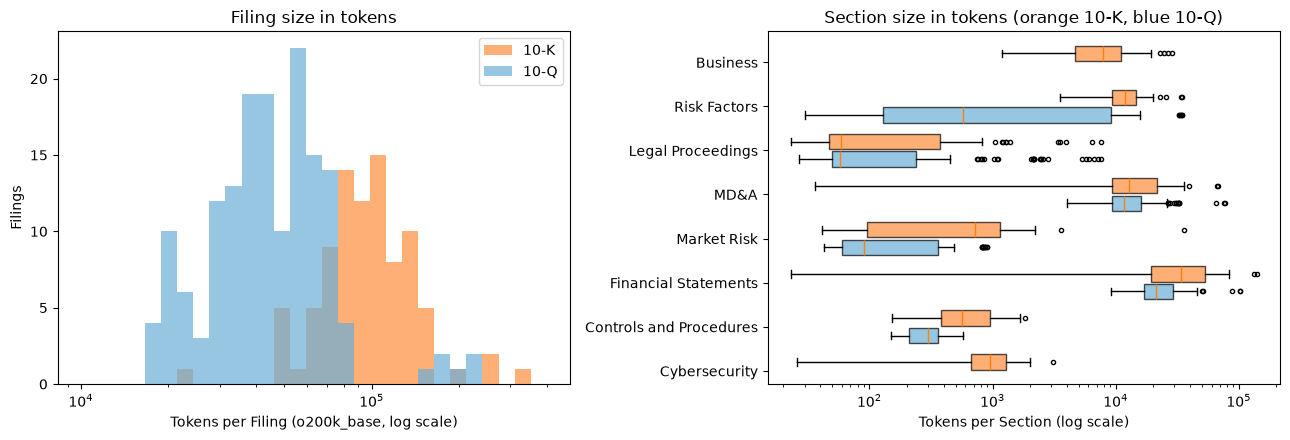

count   min    10%    50%    90%     max
form_type section                                                          
10-K      Business                    86  1202   2647   7824  15578   28837
          Controls and Procedures     86   151    265    567   1372    1829
          Cybersecurity               69    26    530    945   1543    3115
          Financial Statements        85    23     40  33831  67061  139584
          Legal Proceedings           86    23     37     59   1197    7624
          MD&A                        85    36   4124  12736  28880   68160
          Market Risk                 86    41     61    718   1854   35900
          Risk Factors                86  3523   6498  11834  18849   34788
10-Q      Controls and Procedures    157   150    194    300    397     577
          Financial Statements       154  9183  11897  21362  41056  102219
          Legal Proceedings          157    27     34     58   2134    7523
          MD&A                       154  3994   7286  11645  26085   76725
          Market Risk                157    43     48     91    452     900
          Risk Factors               133    30     88    570  12510   34670

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(np.log10(10_000), np.log10(400_000), 30)
for form, colour in [("10-K", "#fd8d3c"), ("10-Q", "#6baed6")]:
    ax1.hist(
        filing_tokens.loc[filing_tokens["form_type"] == form, "tokens"],
        bins=bins,
        alpha=0.7,
        color=colour,
        label=form,
    )
ax1.set_xscale("log")
ax1.set_xlabel("Tokens per Filing (o200k_base, log scale)")
ax1.set_ylabel("Filings")
ax1.set_title("Filing size in tokens")
ax1.legend()

named_tokens = section_tokens[section_tokens["section"].isin(REQUIRED["10-K"])]
for offset, form, colour in [(-0.2, "10-K", "#fd8d3c"), (0.2, "10-Q", "#6baed6")]:
    present = [n for n in REQUIRED["10-K"] if n in REQUIRED[form]]
    ax2.boxplot(
        [
            named_tokens[(named_tokens["form_type"] == form) & (named_tokens["section"] == n)][
                "tokens"
            ]
            for n in present
        ],
        positions=[REQUIRED["10-K"].index(n) + offset for n in present],
        widths=0.35,
        orientation="horizontal",
        patch_artist=True,
        boxprops={"facecolor": colour, "alpha": 0.7},
        flierprops={"markersize": 3},
    )
ax2.set_xscale("log")
ax2.set_yticks(range(len(REQUIRED["10-K"])), REQUIRED["10-K"])
ax2.invert_yaxis()
ax2.set_xlabel("Tokens per Section (log scale)")
ax2.set_title("Section size in tokens (orange 10-K, blue 10-Q)")
fig.tight_layout()
plt.show()

(
    named_tokens.groupby(["form_type", "section"])["tokens"]
    .describe(percentiles=[0.1, 0.5, 0.9])
    .astype(int)[["count", "min", "10%", "50%", "90%", "max"]]
)

The largest outliers, by Filing and by Section:

In [40]:
display(
    filing_tokens.sort_values("tokens", ascending=False)
    .head(10)[["filing_id", "coverage", "chars", "tokens"]]
    .reset_index(drop=True)
)
section_tokens.sort_values("tokens", ascending=False).head(10)[
    ["filing_id", "section", "item", "tokens"]
].reset_index(drop=True)

,filing_id,coverage,chars,tokens
0,JPM_10-K_2025-12-31,snapshot,1276935,322568
1,BAC_10-K_2024-12-31,snapshot,1000722,272294
2,GS_10-K_2024-12-31,snapshot,1160397,265657
3,JPM_10-Q_2025-09-30,snapshot,739425,224169
4,JPM_10-Q_2025-06-30,snapshot,722753,221160
5,MS_10-K_2025-12-31,snapshot,815982,194983
6,JPM_10-Q_2025-03-31,snapshot,642521,189319
7,BAC_10-Q_2025-09-30,snapshot,557863,183141
8,BAC_10-Q_2025-06-30,snapshot,555846,182953
9,PFE_10-K_2023-12-31,tracked,693876,159505


,filing_id,section,item,tokens
0,JPM_10-K_2025-12-31,Other,Item 15,288408
1,JPM_10-Q_2025-09-30,Unsectioned,NaN,220911
2,JPM_10-Q_2025-06-30,Unsectioned,NaN,218889
3,MS_10-K_2025-12-31,Unsectioned,NaN,194983
4,JPM_10-Q_2025-03-31,Unsectioned,NaN,186882
5,BAC_10-K_2024-12-31,Financial Statements,Item 8,139584
6,GS_10-K_2024-12-31,Financial Statements,Item 8,132438
7,INTC_10-K_2025-12-27,Unsectioned,NaN,118725
8,XOM_10-K_2024-12-31,Other,Item 16,107807
9,CVX_10-K_2024-12-31,Other,Item 14,102374


### 5.1 What fits in the Answer Call

The Answer Call is the only generative call per question, so everything retrieved has
to fit in one prompt next to the instructions, the question, the citation metadata
and room for the answer. Current long-context models accept 128k–200k tokens or
more, but cost, latency and the well-known drop in recall for material in the middle
of a long prompt argue for a much smaller retrieved-context budget. The table below
assumes a fixed 4k tokens for instructions, question and answer, and about 40 tokens
of metadata per chunk (Company, Form Type, Report Period, Fiscal Period, Section,
Item), and counts how many chunks of each size fit in budgets from 16k to 128k.

In [41]:
OVERHEAD = 4_000  # instructions, question, answer
CHUNK_HEADER = 40  # citation metadata per chunk
BUDGETS = [16_000, 32_000, 64_000, 128_000]
CHUNK_SIZES = [256, 512, 800, 1_024]
pd.DataFrame(
    {
        f"{b // 1000}k budget": {
            f"{c}-token chunks": (b - OVERHEAD) // (c + CHUNK_HEADER) for c in CHUNK_SIZES
        }
        for b in BUDGETS
    }
)

,16k budget,32k budget,64k budget,128k budget
256-token chunks,40,94,202,418
512-token chunks,21,50,108,224
800-token chunks,14,33,71,147
1024-token chunks,11,26,56,116


And how many whole typical (median) Sections or Filings would fit, which is what a
"just put the Section in the prompt" design would need:

In [42]:
typical = {
    f"{form} {name}": named_tokens[
        (named_tokens["form_type"] == form) & (named_tokens["section"] == name)
    ]["tokens"].median()
    for form, name in [
        ("10-K", "Risk Factors"),
        ("10-K", "MD&A"),
        ("10-K", "Business"),
        ("10-K", "Financial Statements"),
        ("10-Q", "MD&A"),
        ("10-Q", "Financial Statements"),
    ]
}
typical |= {
    f"whole {form} Filing": filing_tokens.loc[filing_tokens["form_type"] == form, "tokens"].median()
    for form in ["10-K", "10-Q"]
}
pd.DataFrame(
    {
        "median tokens": {k: int(v) for k, v in typical.items()},
        **{
            f"fit in {b // 1000}k": {k: round((b - OVERHEAD) / v, 1) for k, v in typical.items()}
            for b in BUDGETS
        },
    }
)

,median tokens,fit in 16k,fit in 32k,fit in 64k,fit in 128k
10-K Risk Factors,11834,1.0,2.4,5.1,10.5
10-K MD&A,12736,0.9,2.2,4.7,9.7
10-K Business,7824,1.5,3.6,7.7,15.8
10-K Financial Statements,33831,0.4,0.8,1.8,3.7
10-Q MD&A,11645,1.0,2.4,5.2,10.6
10-Q Financial Statements,21362,0.6,1.3,2.8,5.8
whole 10-K Filing,97684,0.1,0.3,0.6,1.3
whole 10-Q Filing,43778,0.3,0.6,1.4,2.8


**What the token counts show**

- The cleaned Corpus is about 17M tokens (`o200k_base`), roughly 4.1 characters per
  token. A median 10-K is about 98k tokens and a median 10-Q about 44k; JPMorgan's
  FY2025 10-K is the largest at about 323k tokens, and the large banks (JPM, BAC, GS,
  MS) fill the top of the list. Filings span more than an order of magnitude.
- Substantive Sections are large: a median 10-K Risk Factors is about 12k tokens,
  10-K MD&A about 13k, 10-K Business about 8k and 10-K Financial Statements about 34k.
  The largest Sections are the ones that swallow trailing material (JPMorgan's Item
  15 at 288k tokens, the Unsectioned bodies of JPMorgan's 10-Qs and Morgan Stanley's
  10-K at 187k–221k, ExxonMobil's Item 16 at 108k). Controls and Procedures, 10-Q
  Market Risk and most Legal Proceedings Sections are under 1k tokens.
- At a 32k budget, 33 chunks of 800 tokens fit, or 50 of 512 tokens. That is about
  two typical 10-K Risk Factors Sections, or a third of one typical 10-K. A median
  10-K does not fit in any budget under 128k, and even at 128k only one does.

**So the design does:**

- Never put whole Filings or whole substantive Sections in the Answer Call; always
  retrieve chunks. Whole-Section inclusion is only possible for stubs and small
  Sections (Controls and Procedures, most 10-Q Market Risk and Legal Proceedings).
- Start with prose chunks of about 500–800 tokens with a small overlap, inside Section
  boundaries, and a retrieved-context budget of about 32k tokens (roughly 30–50
  chunks). That leaves room for a cross-Company question to take 5–10 chunks from each
  of five Companies ("the major pharmaceutical companies") without crowding.
  Chunk size is tuned in the retrieval phase; this is the starting point.
- Tables are chunked as whole tables or header-repeating row groups (finding 9), so
  their size is set by the table, capped near the prose chunk size.
- Count tokens with the chosen LLM's own tokenizer once it is known and re-check these
  budgets; keep the tokenizer behind one function so the swap is a one-line change.

## 6. Repetition between periods

Filings repeat themselves: a Company's Risk Factors, accounting policies and controls
language change little from one period to the next. Duplicated text wastes the Answer
Call's context budget and can crowd out the one Filing that actually differs.

Repetition is measured with **8-word shingles**: each text is lower-cased, split
into words, and every run of eight consecutive words is one shingle. The share of a
text's shingles that already appear in an earlier text is the share of it that
repeats. Eight words is long enough that common phrases rarely match by chance and
short enough that a small edit only breaks the shingles around it.

Only Tracked Companies are measured (they are the ones with a sequence of Filings),
in Report Period order.

In [43]:
WORD = re.compile(r"[a-z0-9]+")
SHINGLE_WORDS = 8


def shingles(text):
    words = WORD.findall(text.lower())
    return {hash(tuple(words[i : i + SHINGLE_WORDS])) for i in range(len(words) - 7)}


def repeated_share(text, earlier):
    own = shingles(text)
    return len(own & earlier) / len(own) if own else np.nan


tracked_filings = sorted(
    (f for f in filings if f.coverage == "tracked"), key=lambda f: (f.ticker, f.report_period)
)
print(
    f"{len(tracked_filings)} Filings from "
    f"{len({f.ticker for f in tracked_filings})} Tracked Companies"
)

197 Filings from 13 Tracked Companies


### 6.1 What 10-Q Risk Factors contain

A 10-Q only has to report *material changes* to the risk factors in the last 10-K, so
its Part II, Item 1A takes one of three forms. Each 10-Q's Risk Factors Section is
classed as:

- **none**: the 10-Q has no Part II, Item 1A at all (J&J, ExxonMobil);
- **pointer**: a short paragraph that refers back to the 10-K (sometimes to earlier
  10-Qs too) and adds no risk factors of its own. Concretely, a Section under 2,500
  characters. The gap is clean: the longest such pointer is about 2,100 characters
  (UnitedHealth's, which runs on into Item 2, see below) and the shortest Section that
  adds risk factors is about 2,600;
- **risk text**: the Section states risk factors itself, either as the changed ones
  only ("Other than the risk factors listed below…") or as the full list again.

A pointer is further split by whether it names the 10-K / Annual Report.

In [44]:
POINTER_MAX_CHARS = 2_500
NAMES_10K = re.compile(r"10-K|Annual Report", re.IGNORECASE)


def risk_factors_text(filing):
    return "".join(s.text for s in filing.sections if s.name == "Risk Factors")


def risk_factors_kind(filing):
    text = risk_factors_text(filing)
    if not text:
        return "none"
    if len(text) < POINTER_MAX_CHARS:
        return "pointer to 10-K" if NAMES_10K.search(text) else "pointer elsewhere"
    return "risk text"


rf_10q = pd.DataFrame(
    {
        "filing_id": f.filing_id,
        "ticker": f.ticker,
        "coverage": f.coverage,
        "chars": len(risk_factors_text(f)),
        "kind": risk_factors_kind(f),
    }
    for f in filings
    if f.form_type == "10-Q"
)
kinds = ["pointer to 10-K", "pointer elsewhere", "risk text", "none"]
rf_kinds = (
    pd.DataFrame(
        {
            "All 10-Qs": rf_10q["kind"].value_counts(),
            "Tracked Companies' 10-Qs": rf_10q.loc[
                rf_10q["coverage"] == "tracked", "kind"
            ].value_counts(),
        }
    )
    .reindex(kinds)
    .fillna(0)
    .astype(int)
)
rf_kinds = pd.concat(
    [rf_kinds, (rf_kinds / rf_kinds.sum() * 100).round(0).astype(int).add_suffix(" %")], axis=1
)
display(rf_kinds)

boundary = rf_10q[rf_10q["kind"] != "none"].sort_values("chars")
print(
    "Longest pointer:",
    boundary[boundary["chars"] < POINTER_MAX_CHARS].iloc[-1][["filing_id", "chars"]].to_dict(),
)
print(
    "Shortest risk text:",
    boundary[boundary["chars"] >= POINTER_MAX_CHARS].iloc[0][["filing_id", "chars"]].to_dict(),
)
rf_10q.pivot_table(index="ticker", columns="kind", values="filing_id", aggfunc="count").reindex(
    columns=kinds
).fillna(0).astype(int)

,All 10-Qs,Tracked Companies' 10-Qs,All 10-Qs %,Tracked Companies' 10-Qs %
kind,,,,
pointer to 10-K,64,57,41,38
pointer elsewhere,1,0,1,0
risk text,68,68,43,46
none,24,24,15,16


Longest pointer: {'filing_id': 'UNH_10-Q_2025-03-31', 'chars': 2105}
Shortest risk text: {'filing_id': 'GOOG_10-Q_2024-06-30', 'chars': 2625}


kind,pointer to 10-K,pointer elsewhere,risk text,none
ticker,,,,
AAPL,8,0,4,0
AMZN,0,0,12,0
BAC,3,0,0,0
DIS,4,0,9,0
GOOG,6,0,4,0
JNJ,0,0,0,12
JPM,3,0,0,0
KO,11,0,1,0
MCD,0,1,0,0


UnitedHealth's 10-Q Risk Factors Sections are pointers but run on into Item 2,
because UnitedHealth titles it "Unregistered Sale of Equity Securities" and the
splitter looks for "Unregistered Sales". That makes them about 1,700–2,100
characters instead of a few hundred; it does not change their class here.

### 6.2 Risk Factors, Filing to Filing

For each Tracked Company, every Risk Factors Section that states risk text (every
10-K, and 10-Qs classed as risk text) is compared with all the Company's earlier Risk
Factors text. The heat map shows the share of each Section that repeats earlier text;
pointers and missing Sections are labelled instead. 10-K cells are outlined.

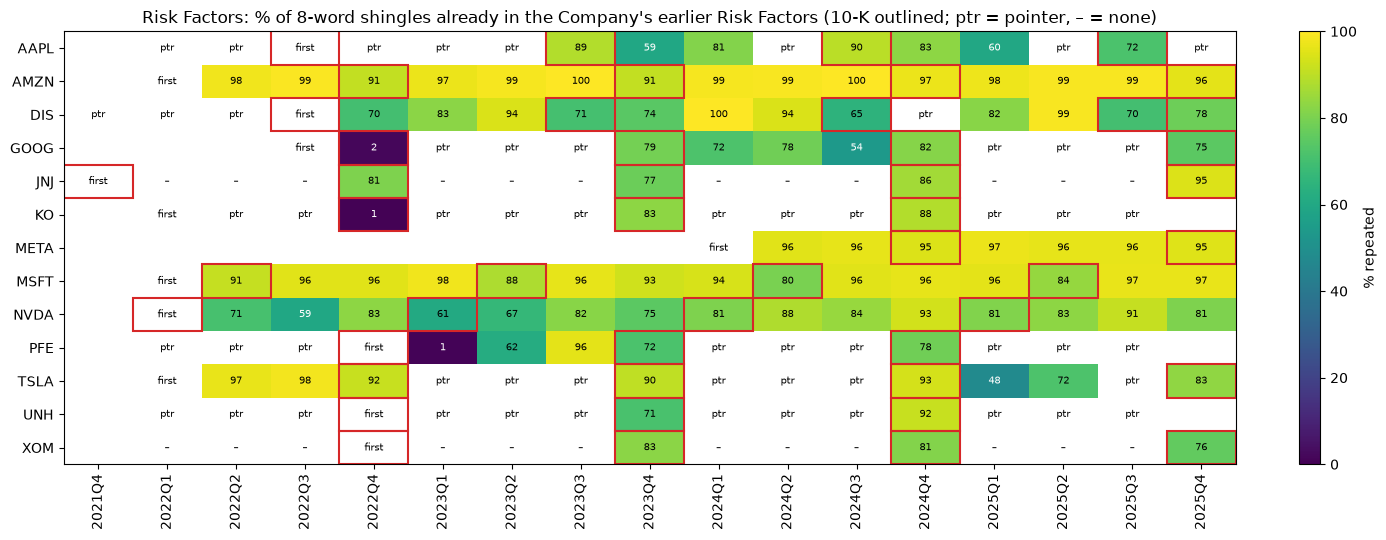

In [45]:
def period_label(d):
    d = d - pd.Timedelta(days=7)  # 52/53-week periods ending a few days into a month
    return f"{d.year}Q{(d.month - 1) // 3 + 1}"


rf_rows = []
earlier_by_ticker = defaultdict(set)
last_10k = {}
for f in tracked_filings:
    text = risk_factors_text(f)
    kind = "risk text" if f.form_type == "10-K" else risk_factors_kind(f)
    row = {
        "ticker": f.ticker,
        "form_type": f.form_type,
        "filing_id": f.filing_id,
        "period": period_label(f.report_period),
        "kind": kind,
        "tokens": len(ENCODING.encode_ordinary(text)),
        "vs_any_earlier": np.nan,
        "vs_previous_10k": np.nan,
    }
    if kind == "risk text":
        if earlier_by_ticker[f.ticker]:
            row["vs_any_earlier"] = repeated_share(text, earlier_by_ticker[f.ticker])
        if f.form_type == "10-K" and f.ticker in last_10k:
            row["vs_previous_10k"] = repeated_share(text, last_10k[f.ticker])
        earlier_by_ticker[f.ticker] |= shingles(text)
        if f.form_type == "10-K":
            last_10k[f.ticker] = shingles(text)
    rf_rows.append(row)
rf_rep = pd.DataFrame(rf_rows)

periods = sorted(rf_rep["period"].unique())
tickers = sorted(rf_rep["ticker"].unique())
grid = rf_rep.pivot_table(index="ticker", columns="period", values="vs_any_earlier", aggfunc="max")
grid = grid.reindex(index=tickers, columns=periods)
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.imshow(grid.to_numpy() * 100, cmap="viridis", vmin=0, vmax=100, aspect="auto")
for r in rf_rep.itertuples():
    y, x = tickers.index(r.ticker), periods.index(r.period)
    if r.kind == "risk text":
        label = "first" if np.isnan(r.vs_any_earlier) else f"{r.vs_any_earlier * 100:.0f}"
    else:
        label = {"pointer to 10-K": "ptr", "pointer elsewhere": "ptr", "none": "–"}[r.kind]
    colour = "white" if r.kind == "risk text" and r.vs_any_earlier < 0.6 else "black"
    ax.text(x, y, label, ha="center", va="center", fontsize=7, color=colour)
    if r.form_type == "10-K":
        ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, lw=1.5, ec="#d62728"))
ax.set_xticks(range(len(periods)), periods, rotation=90)
ax.set_yticks(range(len(tickers)), tickers)
ax.set_title(
    "Risk Factors: % of 8-word shingles already in the Company's earlier Risk Factors "
    "(10-K outlined; ptr = pointer, – = none)"
)
fig.colorbar(ax.images[0], ax=ax, label="% repeated", fraction=0.02)
fig.tight_layout()
plt.show()

In [46]:
tenk = rf_rep[rf_rep["form_type"] == "10-K"]
tenq_text = rf_rep[(rf_rep["form_type"] == "10-Q") & (rf_rep["kind"] == "risk text")]
by_ticker_10k = tenk.groupby("ticker")
by_ticker_10q = tenq_text.groupby("ticker")
summary = pd.DataFrame(
    {
        "10-K vs previous 10-K (median %)": by_ticker_10k["vs_previous_10k"].median() * 100,
        "10-Qs with risk text": by_ticker_10q.size(),
        "their text already said (median %)": by_ticker_10q["vs_any_earlier"].median() * 100,
        "10-Q pointers": rf_rep[rf_rep["kind"].str.startswith("pointer")].groupby("ticker").size(),
        "10-Qs with none": rf_rep[rf_rep["kind"] == "none"].groupby("ticker").size(),
    }
).reindex(tickers)
summary = summary.fillna({c: 0 for c in summary.columns if not c.endswith("(median %)")})
display(summary.round(0).astype("Int64"))

print(
    "All Tracked 10-Ks vs their previous 10-K: median "
    f"{tenk['vs_previous_10k'].median() * 100:.0f}% repeated "
    f"(range {tenk['vs_previous_10k'].min() * 100:.0f}–{tenk['vs_previous_10k'].max() * 100:.0f}%)"
)
print(
    "Tracked 10-Qs with risk text vs earlier Risk Factors: median "
    f"{tenq_text['vs_any_earlier'].median() * 100:.0f}% repeated"
)
full_repeats = tenq_text[tenq_text["vs_any_earlier"] >= 0.9]
print(
    f"10-Qs whose risk text is at least 90% earlier text: {len(full_repeats)} "
    f"({', '.join(sorted(full_repeats['ticker'].unique()))}), "
    f"{full_repeats['tokens'].sum() / 1e6:.1f}M tokens"
)

,10-K vs previous 10-K (median %),10-Qs with risk text,their text already said (median %),10-Q pointers,10-Qs with none
ticker,,,,,
AAPL,86,4,71,8,0
AMZN,94,12,99,0,0
DIS,64,9,83,4,0
GOOG,78,4,72,6,0
JNJ,83,0,<NA>,0,12
KO,85,1,<NA>,11,0
META,89,6,96,0,0
MSFT,77,12,96,0,0
NVDA,59,12,83,0,0


All Tracked 10-Ks vs their previous 10-K: median 80% repeated (range 45–96%)
Tracked 10-Qs with risk text vs earlier Risk Factors: median 94% repeated
10-Qs whose risk text is at least 90% earlier text: 36 (AMZN, DIS, META, MSFT, NVDA, PFE, TSLA), 0.5M tokens


### 6.3 Boilerplate across all Sections

Risk Factors are not the only repeated text. Each Tracked Company Filing is compared
with the Company's previous Filing of the same Form Type (10-K with the previous 10-K,
10-Q with the previous 10-Q), Section by Section: what share of each Section's
shingles already appear anywhere in that previous Filing?

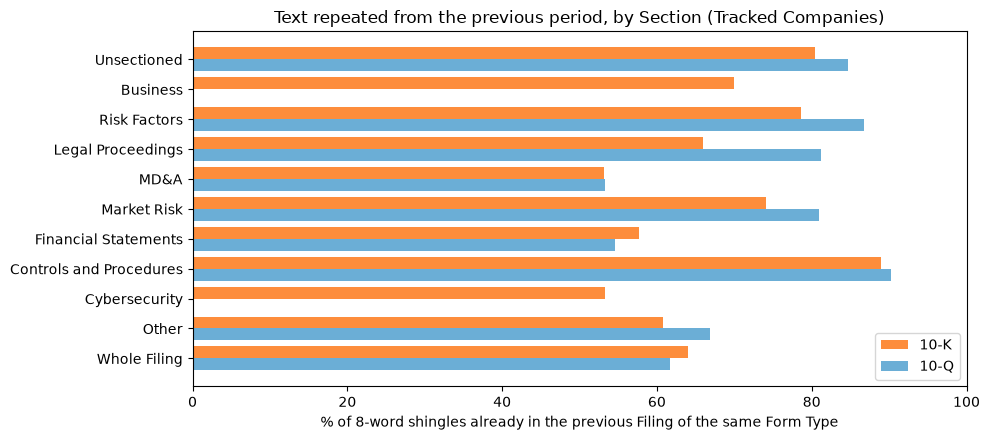

,10-K,10-Q
Unsectioned,80.4,84.7
Business,70.0,NaN
Risk Factors,78.6,86.8
Legal Proceedings,66.0,81.2
MD&A,53.1,53.3
Market Risk,74.1,80.9
Financial Statements,57.7,54.6
Controls and Procedures,88.9,90.2
Cybersecurity,53.3,NaN
Other,60.8,66.8


In [47]:
boiler_rows = []
previous_body = {}
for f in tracked_filings:
    key = (f.ticker, f.form_type)
    if key in previous_body:
        for s in f.sections:
            own = shingles(s.text)
            if own:
                boiler_rows.append(
                    {
                        "ticker": f.ticker,
                        "form_type": f.form_type,
                        "section": s.name,
                        "shingles": len(own),
                        "repeated": len(own & previous_body[key]),
                    }
                )
    previous_body[key] = shingles(f.body)
boiler = pd.DataFrame(boiler_rows)


def repeat_pct(frame):
    sums = frame[["shingles", "repeated"]].sum()
    return round(sums["repeated"] / sums["shingles"] * 100, 1)


section_order = [UNSECTIONED, *REQUIRED["10-K"], "Other"]
by_section = pd.DataFrame(
    {
        form: {
            name: repeat_pct(boiler[(boiler["form_type"] == form) & (boiler["section"] == name)])
            for name in section_order
            if ((boiler["form_type"] == form) & (boiler["section"] == name)).any()
        }
        for form in ["10-K", "10-Q"]
    }
).reindex(section_order)
by_section.loc["Whole Filing"] = [repeat_pct(boiler[boiler["form_type"] == f]) for f in by_section]

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(by_section))
for offset, form, colour in [(-0.2, "10-K", "#fd8d3c"), (0.2, "10-Q", "#6baed6")]:
    ax.barh(y + offset, by_section[form].fillna(0), height=0.4, color=colour, label=form)
ax.set_yticks(y, by_section.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of 8-word shingles already in the previous Filing of the same Form Type")
ax.set_title("Text repeated from the previous period, by Section (Tracked Companies)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

by_section

**What the repetition shows**

- **Risk Factors change slowly from year to year.** A Tracked Company's 10-K Risk
  Factors repeat a median of 80% of the previous 10-K's text word for word (8-word
  shingles), from 94% for Amazon down to 59% for NVIDIA and 64% for Disney, the two
  that rewrite most (45–96% across all 10-Ks).
- **Most 10-Qs add nothing to the 10-K's risk factors.** Of all 157 10-Qs, 64 (41%)
  have a Risk Factors Section that only points back to the 10-K ("There have been no
  material changes…"), one (McDonald's) points elsewhere in the same 10-Q, and 24
  (15%, every J&J and ExxonMobil 10-Q) have none at all. 68 (43%) state risk text.
- **The 10-Qs that do state risk text are mostly repeats.** Their text is a median 94%
  already said in the Company's earlier Risk Factors. Amazon, Microsoft and Meta
  restate their full Risk Factors in every 10-Q (96–99% repeated), and NVIDIA repeats
  long excerpts each quarter. 36 such 10-Qs are at least 90% repeated text, 0.5M
  tokens of duplicates. Only a few 10-Qs (Apple, Alphabet, Disney, Pfizer, Tesla)
  add a short list of genuinely new or changed risks, for example Pfizer's Seagen
  acquisition or Tesla's 2025 tariff risks, and these are where a 10-Q answers a risk
  question the 10-K cannot.
- The dark cells in the heat map are not rewrites: they are a Company's first 10-K in
  the Corpus compared only with a short 10-Q update before it (Alphabet, Coca-Cola,
  Pfizer).
- **Boilerplate runs through every Section.** Compared with the previous Filing of the
  same Form Type, about 60–65% of a Tracked Company's Filing text repeats: about 90%
  of Controls and Procedures, 80–85% of the cover page and other Unsectioned text,
  79–87% of Risk Factors and 66–81% of Legal Proceedings, but only 53% of MD&A and
  55–58% of the Financial Statements, where the figures change each period.

**So the design does:**

- **Deduplicate at index time.** Hash chunks on their normalised text (or a near-
  duplicate key such as MinHash over the same shingles) within each Company. A chunk
  that repeats an earlier Filing's chunk is stored once and carries the list of
  Filings (Report Periods) it appears in, so retrieval sees one copy and citations can
  still name the latest Filing that says it.
- **Diversify at query time.** After retrieval, drop near-duplicate chunks (same
  Company, high shingle overlap) before building the Answer Call prompt, keeping the
  one from the most recent Report Period unless the question asks about a specific
  period. This stops one Company's restated Risk Factors filling the 32k budget.
- **Route risk questions to the 10-K.** For "what are X's risks" questions, filter
  Risk Factors to the Company's latest 10-K, plus any later 10-Q whose Risk Factors
  are risk text (the material changes). Pointer-only 10-Q Risk Factors are indexed
  but tagged as pointers so they are never retrieved as the answer itself.
- **Answer "what changed" questions from the difference.** Questions about how risks
  evolved compare consecutive 10-K Risk Factors; the shingle measure above can
  pre-compute which paragraphs are new in each 10-K, so retrieval can favour new text
  for change questions.

## 7. Can Financial Facts be extracted?

Trend and comparison questions ("How has NVIDIA's revenue changed over the last two
years?") need figures, and figures sit in flattened tables that retrieval and the
Answer Call read poorly (analysis 3). If Financial Facts can be extracted reliably,
they can be handed to the Answer Call as a small, exact table instead. This part
measures that for three metrics, **revenue**, **net income** and **segment
revenue**, over every Filing of the 13 Tracked Companies, through the
`edgar_rag.financial_facts` seam. Per-share values (earnings per share) are not
extracted; the seam's tests check they are never read as net income.

The reference is the SEC's XBRL company-facts API (`make sec-facts` caches it under
`data/derived/`). **The SEC data is used for evaluation only.** It measures how
accurate the extraction is; it is never an answer source, and nothing the system
answers with reads it. Answers stay grounded in the Corpus.

Each Filing is matched to its own SEC facts on the accession number in its source
URL (`.../000032019324000123/...` is `0000320193-24-000123`), the Report Period as
the period end, and the period length: three months for a 10-Q, twelve for a 10-K.
Companies tag the same figure differently, so the reference takes the first tag
present, in this order:

- **revenue:** `Revenues`, `RevenueFromContractWithCustomerExcludingAssessedTax`,
  `RevenueFromContractWithCustomerIncludingAssessedTax`, `SalesRevenueNet`;
- **net income:** `NetIncomeLoss` (net income attributable to the Company), then
  `ProfitLoss` (including noncontrolling interests).

The company-facts API carries no segment breakdown (it holds only facts without
XBRL dimensions), so segment revenue is checked differently, in 7.2.

In [48]:
SEC_TAGS = {
    "revenue": [
        "Revenues",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
        "RevenueFromContractWithCustomerIncludingAssessedTax",
        "SalesRevenueNet",
    ],
    "net_income": ["NetIncomeLoss", "ProfitLoss"],
}


def accession_number(url):
    """The EDGAR accession number in a Filing's source URL."""
    m = re.search(r"/(\d{10})(\d{2})(\d{6})/", url)
    return f"{m[1]}-{m[2]}-{m[3]}"


@cache
def sec_us_gaap(cik):
    return load_company_facts(cik)["facts"]["us-gaap"]


def sec_value(filing, metric):
    """(tag, value) the SEC reports for this metric and Filing's own period, or (None, None)."""
    accn = accession_number(filing.source_url)
    end = filing.report_period.isoformat()
    days = 365 if filing.form_type == "10-K" else 91
    for tag in SEC_TAGS[metric]:
        for fact in sec_us_gaap(filing.cik).get(tag, {}).get("units", {}).get("USD", []):
            if fact["accn"] != accn or fact["end"] != end or "start" not in fact:
                continue
            length = (pd.Timestamp(fact["end"]) - pd.Timestamp(fact["start"])).days
            if abs(length - days) <= 20:
                return tag, fact["val"]
    return None, None


tracked = [f for f in filings if f.coverage == "tracked"]
facts_by_filing = {f.filing_id: extract_financial_facts(f) for f in tracked}

measured_rows = []
for f in tracked:
    for metric in SEC_TAGS:
        fact = next((x for x in facts_by_filing[f.filing_id] if x.metric == metric), None)
        tag, reference = sec_value(f, metric)
        measured_rows.append(
            {
                "metric": metric,
                "ticker": f.ticker,
                "filing_id": f.filing_id,
                "report_period": f.report_period,
                "fiscal_period": f.fiscal_period,
                "form_type": f.form_type,
                "label": fact.label if fact else None,
                "scale": fact.scale if fact else None,
                "extracted": fact.value if fact else None,
                "sec_tag": tag,
                "sec_value": reference,
            }
        )
measured = pd.DataFrame(measured_rows)
# A match is equal to the SEC value within one unit of the table's printed precision
# (under $1 million for a table in millions), i.e. equal at the Filing's own precision.
measured["difference"] = measured["extracted"] - measured["sec_value"]
measured["match"] = measured["difference"].abs() < measured["scale"]
revenue = measured[measured["metric"] == "revenue"]

summary = measured.groupby("metric", sort=False).agg(
    filings=("filing_id", "size"),
    extracted=("extracted", "count"),
    with_sec_value=("sec_value", "count"),
    matching=("match", "sum"),
    exactly_equal=("difference", lambda s: (s == 0).sum()),
)
summary["coverage"] = (summary["extracted"] / summary["filings"]).map("{:.1%}".format)
summary["accuracy"] = (summary["matching"] / summary["extracted"]).map("{:.1%}".format)
summary

,filings,extracted,with_sec_value,matching,exactly_equal,coverage,accuracy
metric,,,,,,,
revenue,197,197,197,197,197,100.0%,100.0%
net_income,197,197,197,197,197,100.0%,100.0%


In [49]:
# Coverage (Filings with an extracted value) and accuracy (extracted values matching
# the SEC) for each Company and metric.
per_company = measured.groupby(["ticker", "metric"], sort=False).agg(
    filings=("filing_id", "size"),
    extracted=("extracted", "count"),
    matching=("match", "sum"),
)
per_company = per_company.unstack("metric")
per_company.columns = [f"{metric}_{what}" for what, metric in per_company.columns]
per_company = per_company[
    ["revenue_filings", "revenue_extracted", "revenue_matching"]
    + ["net_income_extracted", "net_income_matching"]
].rename(columns={"revenue_filings": "filings"})
display(per_company)

# Labels each Company uses for the two metrics, as printed.
measured.pivot_table(
    index="ticker",
    columns="metric",
    values="label",
    aggfunc=lambda s: " / ".join(sorted(set(s.dropna()))),
)

,filings,revenue_extracted,revenue_matching,net_income_extracted,net_income_matching
ticker,,,,,
AAPL,16,16,16,16,16
AMZN,16,16,16,16,16
DIS,17,17,17,17,17
GOOG,14,14,14,14,14
JNJ,17,17,17,17,17
KO,15,15,15,15,15
META,8,8,8,8,8
MSFT,16,16,16,16,16
NVDA,16,16,16,16,16


metric,net_income,revenue
ticker,,
AAPL,Net income,Total net sales
AMZN,Net income / Net income (loss),Total net sales
DIS,Net income (loss) attributable to Disney / Net...,Total revenues
GOOG,Net income,Revenues
JNJ,NET EARNINGS / NET EARNINGS/(LOSS) / Net earni...,Sales to customers / Sales to customers (Note 9)
KO,Net Income Attributable to Shareowners of The ...,Net Operating Revenues
META,Net income,Revenue
MSFT,Net income,Total revenue
NVDA,Net income,Revenue


In [50]:
# Which SEC tag holds each Company's figure, Filing by Filing ("RFC excl. tax" is
# RevenueFromContractWithCustomerExcludingAssessedTax).
pd.crosstab(
    [measured["metric"], measured["ticker"]],
    measured["sec_tag"].replace(
        {"RevenueFromContractWithCustomerExcludingAssessedTax": "RFC excl. tax"}
    ),
)

sec_tag            NetIncomeLoss  RFC excl. tax  Revenues
metric     ticker                                        
net_income AAPL               16              0         0
           AMZN               16              0         0
           DIS                17              0         0
           GOOG               14              0         0
           JNJ                17              0         0
           KO                 15              0         0
           META                8              0         0
           MSFT               16              0         0
           NVDA               16              0         0
           PFE                15              0         0
           TSLA               16              0         0
           UNH                15              0         0
           XOM                16              0         0
revenue    AAPL                0             16         0
           AMZN                0             16         0
           DIS                 0              0        17
           GOOG                0             11         3
           JNJ                 0             17         0
           KO                  0              0        15
           META                0              8         0
           MSFT                0             16         0
           NVDA                0              0        16
           PFE                 0              3        12
           TSLA                0              0        16
           UNH                 0              0        15
           XOM                 0              0        16

In [51]:
mismatches = measured[~measured["match"]]
print(f"{len(mismatches)} mismatches or missing values")
mismatches[["metric", "filing_id", "label", "extracted", "sec_tag", "sec_value", "difference"]]

0 mismatches or missing values


,metric,filing_id,label,extracted,sec_tag,sec_value,difference


### 7.1 Values checked by hand

The SEC data has quirks of its own: a Company can switch tags between Filings, and
a value can be restated later. Matching on the accession number takes each value as
that Filing reported it, which avoids restatements, but the reference is still
another system's reading. As a guard, these values were read by hand from each
Filing's text, one per Company where the layout differs. Revenue: prior year first
(Alphabet), a note-reference column (ExxonMobil, 10-K), a percent-of-sales column
(J&J), a scale in capitals (Pfizer), revenue below its parts (Apple, Microsoft).
Net income: attributable to the Company below the total including noncontrolling
interests (ExxonMobil, Tesla), a net loss labelled "Net (loss) earnings"
(UnitedHealth), a figure written `$3,255` beside a prior-year `$(68)` (J&J).

In [52]:
hand_checked = pd.DataFrame(
    [
        ("revenue", "AAPL_10-K_2024-09-28", "Total net sales", "391,035"),
        ("revenue", "MSFT_10-K_2024-06-30", "Total revenue", "245,122"),
        ("revenue", "KO_10-K_2023-12-31", "Net Operating Revenues", "45,754"),
        ("revenue", "XOM_10-Q_2025-06-30", "Total revenues and other income", "81,506"),
        ("revenue", "JNJ_10-Q_2024-06-30", "Sales to customers (Note 9)", "22,447"),
        ("revenue", "PFE_10-Q_2024-06-30", "Total revenues", "13,283"),
        ("revenue", "GOOG_10-Q_2025-09-30", "Revenues", "102,346"),
        ("revenue", "NVDA_10-Q_2025-10-26", "Revenue", "57,006"),
        ("net_income", "AAPL_10-K_2024-09-28", "Net income", "93,736"),
        ("net_income", "GOOG_10-Q_2025-09-30", "Net income", "34,979"),
        (
            "net_income",
            "XOM_10-Q_2025-06-30",
            "Net income (loss) attributable to ExxonMobil",
            "7,082",
        ),
        (
            "net_income",
            "TSLA_10-Q_2025-06-30",
            "Net income attributable to common stockholders",
            "1,172",
        ),
        (
            "net_income",
            "UNH_10-Q_2024-03-31",
            "Net (loss) earnings attributable to UnitedHealth Group common shareholders",
            "(1,409)",
        ),
        ("net_income", "JNJ_10-Q_2024-03-31", "Net earnings (loss)", "3,255"),
    ],
    columns=["metric", "filing_id", "label_in_filing", "figure_in_millions"],
)
hand_checked["hand_value"] = (
    hand_checked["figure_in_millions"]
    .str.replace(",", "")
    .str.replace(r"\((.*)\)", r"-\1", regex=True)
    .astype(int)
    * 1_000_000
)
hand_checked = hand_checked.merge(
    measured[["metric", "filing_id", "extracted", "sec_value"]], on=["metric", "filing_id"]
)
hand_checked["extracted_ok"] = hand_checked["hand_value"] == hand_checked["extracted"]
hand_checked["sec_ok"] = hand_checked["hand_value"] == hand_checked["sec_value"]
hand_checked

,metric,filing_id,label_in_filing,figure_in_millions,hand_value,extracted,sec_value,extracted_ok,sec_ok
0,revenue,AAPL_10-K_2024-09-28,Total net sales,"391,035",391035000000,391035000000,391035000000,True,True
1,revenue,MSFT_10-K_2024-06-30,Total revenue,"245,122",245122000000,245122000000,245122000000,True,True
2,revenue,KO_10-K_2023-12-31,Net Operating Revenues,"45,754",45754000000,45754000000,45754000000,True,True
3,revenue,XOM_10-Q_2025-06-30,Total revenues and other income,"81,506",81506000000,81506000000,81506000000,True,True
4,revenue,JNJ_10-Q_2024-06-30,Sales to customers (Note 9),"22,447",22447000000,22447000000,22447000000,True,True
5,revenue,PFE_10-Q_2024-06-30,Total revenues,"13,283",13283000000,13283000000,13283000000,True,True
6,revenue,GOOG_10-Q_2025-09-30,Revenues,"102,346",102346000000,102346000000,102346000000,True,True
7,revenue,NVDA_10-Q_2025-10-26,Revenue,"57,006",57006000000,57006000000,57006000000,True,True
8,net_income,AAPL_10-K_2024-09-28,Net income,"93,736",93736000000,93736000000,93736000000,True,True
9,net_income,GOOG_10-Q_2025-09-30,Net income,"34,979",34979000000,34979000000,34979000000,True,True


In [53]:
# The source row of each hand-checked value, as the extractor found it in the cleaned body.
by_id = {f.filing_id: f for f in tracked}
for metric, filing_id in hand_checked[["metric", "filing_id"]].itertuples(index=False):
    fact = next(x for x in facts_by_filing[filing_id] if x.metric == metric)
    row = by_id[filing_id].body[fact.offset :].split("\n", 1)[0]
    print(f"{metric:10} {filing_id:22} {row[:100]}")

revenue    AAPL_10-K_2024-09-28   Total net sales | 391,035 |  |  | 383,285 |  |  | 394,328 |
revenue    MSFT_10-K_2024-06-30   Total revenue |  |  | 245,122 |  |  |  | 211,915 |  |  |  | 198,270 |
revenue    KO_10-K_2023-12-31     Net Operating Revenues | $ | 45,754 |  | $ | 43,004 |  | $ | 38,655 |
revenue    XOM_10-Q_2025-06-30    Total revenues and other income | 81,506 |  | 93,060 |  | 164,636 |  | 176,143 |
revenue    JNJ_10-Q_2024-06-30    Sales to customers (Note 9) |  | $22,447 |  | 100.0 | % |  | $21,519 |  | 100.0 | %
revenue    PFE_10-Q_2024-06-30    Total revenues |  | 13,283 |  |  | 13,007 |  |  | 28,162 |  |  | 31,492 |
revenue    GOOG_10-Q_2025-09-30   Revenues | $ | 88,268 |  |  | $ | 102,346 |  |  | $ | 253,549 |  |  | $ | 289,007 |
revenue    NVDA_10-Q_2025-10-26   Revenue | $ | 57,006 |  |  | $ | 35,082 |  |  | $ | 147,811 |  |  | $ | 91,166 |
net_income AAPL_10-K_2024-09-28   Net income | $ | 93,736 |  |  | $ | 96,995 |  |  | $ | 99,803 |
net_income GOOG_10-Q_2025-

### 7.2 Segment revenue

A segment's revenue is read from the Filing's segment table: either rows of figures
above a row equal to revenue (Microsoft, Alphabet, Apple, Disney), or a heading per
segment followed by its own revenue row (Amazon, Meta, Tesla). The text introducing
the table must call them segments, which keeps out tables of products, geographies
and end markets that also add up to revenue (Apple's net sales by category,
NVIDIA's revenue by market platform). The segments, with any reconciling rows
(eliminations, hedging), must add up to the Filing's revenue fact, which 7 has
matched to the SEC for every Filing.

Without an SEC reference, accuracy is checked two ways: every extracted set
reconciles to SEC-matched revenue by construction, and values read by hand from the
Filing text must agree.

In [54]:
segment_facts = pd.DataFrame(
    {
        "ticker": x.ticker,
        "filing_id": x.filing_id,
        "report_period": x.report_period,
        "segment": x.segment,
        "value": x.value,
    }
    for fs in facts_by_filing.values()
    for x in fs
    if x.metric == "segment_revenue"
)
segment_coverage = (
    pd.DataFrame({"ticker": f.ticker, "filing_id": f.filing_id} for f in tracked)
    .assign(with_segments=lambda d: d["filing_id"].isin(segment_facts["filing_id"]))
    .groupby("ticker")
    .agg(filings=("filing_id", "size"), with_segments=("with_segments", "sum"))
)
covered = segment_coverage["with_segments"].sum()
print(
    f"Segment revenue extracted from {covered} of {segment_coverage['filings'].sum()} "
    f"Tracked Company Filings ({covered / segment_coverage['filings'].sum():.1%}), "
    f"{(segment_coverage['with_segments'] > 0).sum()} of {len(segment_coverage)} Companies"
)
segment_coverage

Segment revenue extracted from 101 of 197 Tracked Company Filings (51.3%), 7 of 13 Companies


,filings,with_segments
ticker,,
AAPL,16,16
AMZN,16,16
DIS,17,15
GOOG,14,14
JNJ,17,0
KO,15,0
META,8,8
MSFT,16,16
NVDA,16,0


In [55]:
# The segments each Company reports, and the Report Periods each set covers. A change
# of set is a reorganisation of the Company's segments.
segment_sets = (
    segment_facts.groupby(["ticker", "filing_id", "report_period"])["segment"]
    .agg(" / ".join)
    .reset_index()
    .groupby(["ticker", "segment"])
    .agg(
        filings=("filing_id", "size"),
        first=("report_period", "min"),
        last=("report_period", "max"),
    )
    .sort_values(["ticker", "first"])
)
segment_sets

filings  \
ticker segment                                                       
AAPL   Americas / Europe / Greater China / Japan / Res...       16   
AMZN   North America / International / AWS                      16   
DIS    Disney Media and Entertainment Distribution / D...        5   
       Entertainment / Sports / Experiences                     10   
GOOG   Google Services / Google Cloud / Other Bets              14   
META   Family of Apps / Reality Labs                             8   
MSFT   Productivity and Business Processes / Intellige...       16   
TSLA   Automotive segment / Energy generation and stor...       16   

                                                                first  \
ticker segment                                                          
AAPL   Americas / Europe / Greater China / Japan / Res...  2022-03-26   
AMZN   North America / International / AWS                 2022-03-31   
DIS    Disney Media and Entertainment Distribution / D...  2022-01-01   
       Entertainment / Sports / Experiences                2023-09-30   
GOOG   Google Services / Google Cloud / Other Bets         2022-09-30   
META   Family of Apps / Reality Labs                       2024-03-31   
MSFT   Productivity and Business Processes / Intellige...  2022-03-31   
TSLA   Automotive segment / Energy generation and stor...  2022-03-31   

                                                                 last  
ticker segment                                                         
AAPL   Americas / Europe / Greater China / Japan / Res...  2025-12-27  
AMZN   North America / International / AWS                 2025-12-31  
DIS    Disney Media and Entertainment Distribution / D...  2023-07-01  
       Entertainment / Sports / Experiences                2025-12-27  
GOOG   Google Services / Google Cloud / Other Bets         2025-12-31  
META   Family of Apps / Reality Labs                       2025-12-31  
MSFT   Productivity and Business Processes / Intellige...  2025-12-31  
TSLA   Automotive segment / Energy generation and stor...  2025-12-31

In [56]:
# The segments add up to the Filing's revenue (with any reconciling rows), which is
# what the extractor requires. Shown here as the share of revenue the named segments
# account for: the rest is eliminations, hedging and similar rows.
segment_share = (
    segment_facts.groupby("filing_id")["value"]
    .sum()
    .to_frame("segments_total")
    .join(revenue.set_index("filing_id")[["ticker", "sec_value"]])
)
segment_share["share_of_revenue"] = segment_share["segments_total"] / segment_share["sec_value"]
segment_share.groupby("ticker")["share_of_revenue"].agg(["min", "max"]).round(4)

,min,max
ticker,,
AAPL,1.0000,1.0000
AMZN,1.0000,1.0000
DIS,1.0000,1.0209
GOOG,0.9908,1.0020
META,1.0000,1.0000
MSFT,1.0000,1.0000
TSLA,1.0000,1.0000


In [57]:
segment_hand_checked = pd.DataFrame(
    [
        ("MSFT_10-Q_2025-03-31", "Productivity and Business Processes", "29,944"),
        ("MSFT_10-Q_2025-03-31", "Intelligent Cloud", "26,751"),
        ("MSFT_10-Q_2025-03-31", "More Personal Computing", "13,371"),
        ("AMZN_10-Q_2025-06-30", "North America", "100,068"),
        ("AMZN_10-Q_2025-06-30", "AWS", "30,873"),
        ("GOOG_10-Q_2025-06-30", "Google Cloud", "13,624"),
        ("META_10-Q_2025-06-30", "Reality Labs", "370"),
        ("TSLA_10-Q_2025-06-30", "Energy generation and storage segment", "2,789"),
        ("AAPL_10-Q_2025-06-28", "Greater China", "15,369"),
        ("DIS_10-K_2023-09-30", "Experiences", "32,549"),
    ],
    columns=["filing_id", "segment", "figure_in_millions"],
)
segment_hand_checked["hand_value"] = (
    segment_hand_checked["figure_in_millions"].str.replace(",", "").astype(int) * 1_000_000
)
segment_hand_checked = segment_hand_checked.merge(
    segment_facts[["filing_id", "segment", "value"]], on=["filing_id", "segment"], how="left"
)
segment_hand_checked["extracted_ok"] = (
    segment_hand_checked["hand_value"] == segment_hand_checked["value"]
)
segment_hand_checked

,filing_id,segment,figure_in_millions,hand_value,value,extracted_ok
0,MSFT_10-Q_2025-03-31,Productivity and Business Processes,"29,944",29944000000,29944000000,True
1,MSFT_10-Q_2025-03-31,Intelligent Cloud,"26,751",26751000000,26751000000,True
2,MSFT_10-Q_2025-03-31,More Personal Computing,"13,371",13371000000,13371000000,True
3,AMZN_10-Q_2025-06-30,North America,"100,068",100068000000,100068000000,True
4,AMZN_10-Q_2025-06-30,AWS,"30,873",30873000000,30873000000,True
5,GOOG_10-Q_2025-06-30,Google Cloud,"13,624",13624000000,13624000000,True
6,META_10-Q_2025-06-30,Reality Labs,370,370000000,370000000,True
7,TSLA_10-Q_2025-06-30,Energy generation and storage segment,"2,789",2789000000,2789000000,True
8,AAPL_10-Q_2025-06-28,Greater China,"15,369",15369000000,15369000000,True
9,DIS_10-K_2023-09-30,Experiences,"32,549",32549000000,32549000000,True


Six Companies yield no segment revenue. Each was inspected by hand; none is a
misread, each is a layout the rules don't handle:

- **KO, NVDA, XOM:** segments are the **columns** of the segment table, not its
  rows (Coca-Cola's regions; NVIDIA's Compute & Networking and Graphics;
  ExxonMobil's Upstream, Energy, Chemical and Specialty Products, each split U.S. /
  non-U.S.).
- **JNJ:** segment sales are broken down by franchise and by U.S. / International
  rows; the segment totals sit in columns of a later table.
- **PFE:** revenues, earnings and depreciation sit side by side in one table, and
  the reconciling rows leave the revenue column empty, so the rows don't line up.
- **UNH:** the MD&A table's percentage-change cells carry a `%` on some rows and not
  others, so rows of one table have different widths; the note gives segments as
  columns.

Two Disney Filings (the FY2022 10-K and the Q2 FY2022 10-Q) are missed for a
different reason, and rightly: their segments add up to "segment revenues", which a
separate table reconciles to total revenue through a $1,023 million content-licence
termination charged outside the segments. The segment table alone does not add up to
revenue, so the extractor returns nothing rather than a set it cannot check.

### 7.3 A 10-K reports the year, not its fourth quarter

A quarterly series needs every quarter, but the 10-K reports the fiscal year.
Its fourth quarter is the year less the three quarters reported in that year's
10-Qs. NVIDIA's revenue over the Corpus shows the derivation:

In [58]:
nvda = revenue[revenue["ticker"] == "NVDA"][
    ["report_period", "fiscal_period", "form_type", "extracted"]
]
nvda = nvda.sort_values("report_period").reset_index(drop=True)
nvda["fiscal_year"] = nvda["fiscal_period"].str[-6:]
nvda["quarter_revenue_bn"] = nvda["extracted"] / 1e9
for i, row in nvda[nvda["form_type"] == "10-K"].iterrows():
    quarters = nvda[(nvda["fiscal_year"] == row["fiscal_year"]) & (nvda["form_type"] == "10-Q")]
    nvda.loc[i, "quarter_revenue_bn"] = (
        (row["extracted"] - quarters["extracted"].sum()) / 1e9 if len(quarters) == 3 else np.nan
    )
nvda.round(3)

,report_period,fiscal_period,form_type,extracted,fiscal_year,quarter_revenue_bn
0,2022-01-30,FY2022,10-K,26914000000,FY2022,NaN
1,2022-05-01,Q1 FY2023,10-Q,8288000000,FY2023,8.288
2,2022-07-31,Q2 FY2023,10-Q,6704000000,FY2023,6.704
3,2022-10-30,Q3 FY2023,10-Q,5931000000,FY2023,5.931
4,2023-01-29,FY2023,10-K,26974000000,FY2023,6.051
5,2023-04-30,Q1 FY2024,10-Q,7192000000,FY2024,7.192
6,2023-07-30,Q2 FY2024,10-Q,13507000000,FY2024,13.507
7,2023-10-29,Q3 FY2024,10-Q,18120000000,FY2024,18.120
8,2024-01-28,FY2024,10-K,60922000000,FY2024,22.103
9,2024-04-28,Q1 FY2025,10-Q,26044000000,FY2025,26.044


**What the extraction shows**

- **Revenue and net income: complete and exact.** Both are extracted from all 197
  Filings of the 13 Tracked Companies, 10-Ks and 10-Qs, and every value equals the
  SEC's value for the same Filing and period to the dollar (the tolerance allowed is
  under one printed unit, $1 million for a table in millions, and none was needed).
  There are no mismatches to list. All 14 hand-checked values agree with both.
- **Net income needs the right row, not just a net income row.** Six Companies
  report a total including noncontrolling interests and then the part attributable
  to the Company (ExxonMobil, Coca-Cola, Pfizer, Tesla, Disney, UnitedHealth); the
  SEC's `NetIncomeLoss` is the attributable figure, and so is what a reader means by
  "net income". Per-share rows ("Net income per share - diluted") sit in the same
  table under the same "in millions" title and must never be read as net income.
- **Segment revenue: exact where found, found for half the Filings.** It is
  extracted from 101 of the 197 Filings (51%), for 7 of the 13 Companies: Apple,
  Amazon, Alphabet, Meta, Microsoft and Tesla in every Filing, Disney in 15 of 17.
  Every extracted set adds up to the SEC-matched revenue (with eliminations or
  hedging) and all 10 hand-checked values agree. The other six Companies (J&J,
  Coca-Cola, NVIDIA, Pfizer, UnitedHealth, ExxonMobil) yield nothing: their segments
  are the columns of a table, or are split across rows the rules can't add up. The
  SEC's company-facts data has no segment breakdown, so a wider check needs the
  hand-checked values or another reference.
- **Segments change.** Disney reorganised from two segments (Disney Media and
  Entertainment Distribution; Disney Parks, Experiences and Products) to three
  (Entertainment, Sports, Experiences) from FY2023, so a segment trend can't run
  across the change.
- **Rules are enough, but they encode the Corpus.** Thirteen Companies use eight
  revenue labels and 17 net income labels, put the current year in the first or
  the last column, add note-reference or percent-of-sales columns, state the scale in
  the title, a header row or in capitals, write negatives as `(68)` or `$(68)`, and
  lay segment tables out three different ways. These rules were written against
  these 13 Companies; the 41 Snapshot Companies are not measured here. The extractor
  returns nothing rather than a guess when a step is ambiguous.
- **The SEC's own tagging varies too.** Revenue is `Revenues` for some Companies and
  `RevenueFromContractWithCustomerExcludingAssessedTax` for others, and Alphabet and
  Pfizer switch between them from one Filing to the next. A reference built on one
  tag would have reported false mismatches. Net income is `NetIncomeLoss` throughout.
- **A 10-K gives the year.** A quarterly series needs the fourth quarter derived as
  the fiscal year less its three 10-Q quarters (NVIDIA's Q4 FY2025: $39.3bn).

**So the design does:**

- **Build a SQLite Financial Facts store** of the Tracked Companies' revenue, net
  income and segment revenue, rebuilt from the Corpus at index time, and query it
  with fixed, parameterised queries chosen by the rule-based query parser before the
  single Answer Call. Never text-to-SQL, which would need a second LLM call. The
  decision and its alternatives are in
  [ADR 0001](../../docs/adr/0001-sqlite-financial-facts-store.md).
- **Hand trend questions exact figures.** For a revenue, net income or segment
  question, the facts for the Company and window go into the Answer Call's context as
  a small table, each with its Filing ID, Report Period, Fiscal Period and label as
  printed, next to the retrieved MD&A text. Quarterly series derive the fourth
  quarter from the 10-K and say so.
- **Fall back to text, and say so, where the store has no fact.** Segment questions
  for the six Companies without segment facts, any other metric, and every Snapshot
  Company are answered from retrieved table and MD&A chunks, and the answer says the
  figure was read from the Filing text rather than from extracted Financial Facts.
- **Never answer from the SEC data.** It stays an evaluation reference, cached under
  `data/derived/` and fetched only by `make sec-facts`.

## 8. Coverage of the example questions

Can the Corpus answer the kind of question the Client will ask, and where can't it?
Each example question from the brief is traced to the Filings (by Filing ID and
Report Period) and the Sections that should answer it, using only rules a
rule-based query parser could apply before the single Answer Call:

- **Company names** map to tickers; **sector phrases** ("the major pharmaceutical
  companies") resolve through the curated Sector table, on its industry column.
- **"Latest" or no time phrase** means each Company's latest 10-K by Report Period,
  plus the 10-Qs after it, which may update its risk factors.
- **"The last two years"** means the Filings whose Report Period falls in the two
  years up to the Company's latest Report Period in the Corpus. 52/53-week years
  drift by a few days, so the window start gets a week's slack; a Tracked Company
  then has exactly eight Filings in it (one per quarter-end).
- **Topics map to Sections:** risk → Risk Factors; revenue and outlook → MD&A, with
  the Financial Statements for the figures; regulation and how a Company responds →
  Risk Factors, Business (where 10-Ks describe government regulation) and MD&A.

A Section is **found**, a **stub** (under 1,000 characters, usually a pointer
elsewhere, see analysis 4.2), or **not found** (a `section_not_found` diagnostic or
a genuinely absent Item).

In [59]:
company_filings = {}
for f in sorted(filings, key=lambda f: f.report_period):
    company_filings.setdefault(f.ticker, []).append(f)
sector_by_ticker = {r.ticker: r for r in load_sector_table()}


def latest_filing(ticker, form_type="10-K"):
    """The Company's Filing of this Form Type with the latest Report Period."""
    return [f for f in company_filings[ticker] if f.form_type == form_type][-1]


def tenqs_after_latest_10k(ticker):
    """The 10-Qs after the Company's latest 10-K, which may update its risk factors."""
    cutoff = latest_filing(ticker).report_period
    return [
        f for f in company_filings[ticker] if f.form_type == "10-Q" and f.report_period > cutoff
    ]


def last_two_years(ticker):
    """The Filings in the two years up to the Company's latest Report Period."""
    anchor = pd.Timestamp(company_filings[ticker][-1].report_period)
    start = (anchor - pd.DateOffset(years=2) + pd.Timedelta(days=7)).date()
    return [f for f in company_filings[ticker] if f.report_period > start]


def in_industries(*industries):
    return sorted(t for t, r in sector_by_ticker.items() if r.industry in industries)


def section_status(filing, name):
    matches = [s for s in filing.sections if s.name == name]
    if not matches:
        return None, 0, "not found"
    chars = sum(len(s.text) for s in matches)
    return matches[0].item, chars, "stub" if chars < STUB_CHARS else "found"


def trace(plan):
    """One row per Filing and Section a question needs. `plan` is [(Filings, Sections)]."""
    return pd.DataFrame(
        {
            "ticker": f.ticker,
            "filing_id": f.filing_id,
            "report_period": f.report_period,
            "fiscal_period": f.fiscal_period,
            "coverage": f.coverage,
            "section": name,
            "item": item,
            "chars": chars,
            "status": status,
        }
        for planned, names in plan
        for f in planned
        for name in names
        for item, chars, status in [section_status(f, name)]
    )


def latest_annual_and_updates(tickers, sections):
    return [
        ([latest_filing(t) for t in tickers], sections),
        ([f for t in tickers for f in tenqs_after_latest_10k(t)], ["Risk Factors"]),
    ]

### 8.1 Risk factors of Apple, Tesla and JPMorgan

_"What are the primary risk factors facing Apple, Tesla, and JPMorgan, and how do they
compare?"_

In [60]:
q1 = trace(latest_annual_and_updates(["AAPL", "TSLA", "JPM"], ["Risk Factors"]))
q1

,ticker,filing_id,report_period,fiscal_period,coverage,section,item,chars,status
0,AAPL,AAPL_10-K_2025-09-27,2025-09-27,FY2025,tracked,Risk Factors,Item 1A,67927,found
1,TSLA,TSLA_10-K_2025-12-31,2025-12-31,FY2025,tracked,Risk Factors,Item 1A,83641,found
2,JPM,JPM_10-K_2025-12-31,2025-12-31,FY2025,snapshot,Risk Factors,Item 1A,111696,found
3,AAPL,AAPL_10-Q_2025-12-27,2025-12-27,Q1 FY2026,tracked,Risk Factors,"Part II, Item 1A",412,stub


In [61]:
aapl_update = tenqs_after_latest_10k("AAPL")[0]
print(aapl_update.filing_id, [s.text for s in aapl_update.sections if s.name == "Risk Factors"])

AAPL_10-Q_2025-12-27 ['Item 1A.\xa0\xa0\xa0\xa0Risk FactorsThe Company’s business, reputation, results of operations, financial condition and stock price can be materially and adversely affected by a number of factors, whether currently known or unknown, including those described in Part I, Item 1A of the 2025 Form 10-K under the heading “Risk Factors.” There have been no material changes to the Company’s risk factors since the 2025 Form 10-K.']


Every Company has a full Item 1A in its latest 10-K, and all three are FY2025. But
Apple's fiscal year ended on 27 September 2025, a quarter before Tesla's and
JPMorgan's (31 December 2025). Apple's later 10-Q (Q1 FY2026) only says there have
been no material changes. JPMorgan is a Snapshot Company, which doesn't matter for a
point-in-time comparison. The three Risk Factors Sections hold about 263,000
characters between them, far more than an Answer Call should carry, so retrieval
must pick passages per Company rather than whole Sections.

### 8.2 NVIDIA's revenue and outlook over the last two years

_"How has NVIDIA's revenue and growth outlook changed over the last two years?"_

In [62]:
q2 = trace([(last_two_years("NVDA"), ["MD&A", "Financial Statements"])])
q2

,ticker,filing_id,report_period,fiscal_period,coverage,section,item,chars,status
0,NVDA,NVDA_10-K_2024-01-28,2024-01-28,FY2024,tracked,MD&A,Item 7,41257,found
1,NVDA,NVDA_10-K_2024-01-28,2024-01-28,FY2024,tracked,Financial Statements,Item 8,206,stub
2,NVDA,NVDA_10-Q_2024-04-28,2024-04-28,Q1 FY2025,tracked,MD&A,"Part I, Item 2",34216,found
3,NVDA,NVDA_10-Q_2024-04-28,2024-04-28,Q1 FY2025,tracked,Financial Statements,"Part I, Item 1",55368,found
4,NVDA,NVDA_10-Q_2024-07-28,2024-07-28,Q2 FY2025,tracked,MD&A,"Part I, Item 2",40422,found
5,NVDA,NVDA_10-Q_2024-07-28,2024-07-28,Q2 FY2025,tracked,Financial Statements,"Part I, Item 1",60728,found
6,NVDA,NVDA_10-Q_2024-10-27,2024-10-27,Q3 FY2025,tracked,MD&A,"Part I, Item 2",37227,found
7,NVDA,NVDA_10-Q_2024-10-27,2024-10-27,Q3 FY2025,tracked,Financial Statements,"Part I, Item 1",60933,found
8,NVDA,NVDA_10-K_2025-01-26,2025-01-26,FY2025,tracked,MD&A,Item 7,38776,found
9,NVDA,NVDA_10-K_2025-01-26,2025-01-26,FY2025,tracked,Financial Statements,Item 8,206,stub


In [63]:
nvda_outlook = {
    f.filing_id: len(re.findall(r"outlook", f.body, re.IGNORECASE)) for f in company_filings["NVDA"]
}
print("Filings mentioning an 'outlook':", {k: v for k, v in nvda_outlook.items() if v})
print("Latest NVIDIA 10-K:", latest_filing("NVDA").filing_id, latest_filing("NVDA").fiscal_period)

Filings mentioning an 'outlook': {'NVDA_10-Q_2022-07-31': 4}
Latest NVIDIA 10-K: NVDA_10-K_2025-01-26 FY2025


"The last two years" resolves to **eight Report Periods, 28 January 2024 to
26 October 2025**: NVIDIA's Q4 FY2024 (its FY2024 10-K) through Q3 FY2026, two
10-Ks and six 10-Qs. The window is anchored on NVIDIA's latest Filing in the Corpus,
not on today's date. The Corpus ends with Filings made up to 19 February 2026, and
NVIDIA's FY2026 10-K (year ending January 2026) is not in it. Every Filing in the
window has a full MD&A. The 10-Ks' Item 8 is only a pointer to the financial
statements at the back of the Filing, so revenue figures for the two fiscal years come
from the whole Filing or from MD&A.

**Outlook is a gap.** NVIDIA gives its revenue outlook in its quarterly earnings
release, which is not a 10-K or 10-Q. The word appears in a single Filing, the Q2
FY2023 10-Q (outside the window), and only to say that the outlook "provided on
August 24, 2022" may not be met. An answer about the growth outlook must be built from
MD&A commentary (demand, supply, export controls) and Risk Factors, and must say so.

### 8.3 Regulatory risk at the major pharmaceutical companies

_"What regulatory risks do the major pharmaceutical companies face, and how are they
addressing them?"_

In [64]:
pharma = in_industries("Pharmaceuticals", "Biotechnology")
print("The major pharmaceutical companies:", ", ".join(pharma))
q3 = trace(latest_annual_and_updates(pharma, ["Risk Factors", "Business", "MD&A"]))
q3

The major pharmaceutical companies: ABBV, JNJ, LLY, MRK, PFE


,ticker,filing_id,report_period,fiscal_period,coverage,section,item,chars,status
0,ABBV,ABBV_10-K_2024-12-31,2024-12-31,FY2024,snapshot,Risk Factors,Item 1A,58525,found
1,ABBV,ABBV_10-K_2024-12-31,2024-12-31,FY2024,snapshot,Business,Item 1,70625,found
2,ABBV,ABBV_10-K_2024-12-31,2024-12-31,FY2024,snapshot,MD&A,Item 7,66931,found
3,JNJ,JNJ_10-K_2025-12-28,2025-12-28,FY2025,tracked,Risk Factors,Item 1A,43293,found
4,JNJ,JNJ_10-K_2025-12-28,2025-12-28,FY2025,tracked,Business,Item 1,34532,found
5,JNJ,JNJ_10-K_2025-12-28,2025-12-28,FY2025,tracked,MD&A,Item 7,69511,found
6,LLY,LLY_10-K_2025-12-31,2025-12-31,FY2025,snapshot,Risk Factors,Item 1A,77376,found
7,LLY,LLY_10-K_2025-12-31,2025-12-31,FY2025,snapshot,Business,Item 1,84158,found
8,LLY,LLY_10-K_2025-12-31,2025-12-31,FY2025,snapshot,MD&A,Item 7,49619,found
9,MRK,MRK_10-K_2024-12-31,2024-12-31,FY2024,snapshot,Risk Factors,Item 1A,74213,found


In [65]:
REGULATORY = re.compile(
    r"regulat|FDA|Inflation Reduction Act|drug pric|Medicare negotiation", re.IGNORECASE
)
pd.DataFrame(
    {
        latest_filing(t).filing_id: Counter(
            {s.name: len(REGULATORY.findall(s.text)) for s in latest_filing(t).sections}
        )
        for t in pharma
    }
).fillna(0).astype(int).loc[["Risk Factors", "Business", "MD&A", "Financial Statements"]]

,ABBV_10-K_2024-12-31,JNJ_10-K_2025-12-28,LLY_10-K_2025-12-31,MRK_10-K_2024-12-31,PFE_10-K_2024-12-31
Risk Factors,63,44,94,76,100
Business,112,41,114,109,90
MD&A,25,11,29,40,50
Financial Statements,32,24,16,62,37


The Sector table resolves "the major pharmaceutical companies" to **AbbVie, Johnson &
Johnson, Eli Lilly, Merck and Pfizer**: the Companies in the Pharmaceuticals
industry plus AbbVie (Biotechnology, but SIC 2834 like the others; see Client
question 5). UnitedHealth and Thermo Fisher are Health Care but not drug makers.

Regulatory content is spread over three Sections: the risks themselves are in Risk
Factors, while Business (government regulation, pricing) and MD&A (the effect of the
Inflation Reduction Act's Medicare price negotiation) hold how each Company describes
and responds to them. All three are found in every pharma 10-K.

**The latest 10-Ks are not all from the same year.** J&J and Lilly have FY2025 10-Ks;
AbbVie, Merck and Pfizer only FY2024. Pfizer's three 2025 10-Qs only point back to
its FY2024 10-K. Only J&J and Pfizer are Tracked Companies, so "how are they
addressing them" over time can be answered for those two alone.

### 8.4 Variant questions

Five variants of the same kinds test how general these findings are: a trend asked
of a Snapshot Company, a trend for the borderline Tracked Company, two more sector
phrases, and a Company whose only Filing is stale.

In [66]:
banks = in_industries("Banks")
oil_majors = in_industries("Oil, Gas & Consumable Fuels")
print("The major banks:", ", ".join(banks), "| The oil majors:", ", ".join(oil_majors))

variants = {
    "V1 How has JPMorgan's revenue changed over the last two years?": trace(
        [(last_two_years("JPM"), ["MD&A", "Financial Statements"])]
    ),
    "V2 How has Meta's revenue changed over the last two years?": trace(
        [(last_two_years("META"), ["MD&A"])]
    ),
    "V3 What are the main risks facing the major banks?": trace(
        latest_annual_and_updates(banks, ["Risk Factors"])
    ),
    "V4 What regulatory risks do the oil majors face?": trace(
        latest_annual_and_updates(oil_majors, ["Risk Factors", "Business", "MD&A"])
    ),
    "V5 How has General Electric performed recently?": trace([([latest_filing("GE")], ["MD&A"])]),
}
pd.concat(variants, names=["question", None]).droplevel(1)

The major banks: BAC, JPM | The oil majors: CVX, XOM


,ticker,filing_id,report_period,fiscal_period,coverage,section,item,chars,status
question,,,,,,,,,
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-03-31,2025-03-31,Q1 FY2025,snapshot,MD&A,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-03-31,2025-03-31,Q1 FY2025,snapshot,Financial Statements,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-06-30,2025-06-30,Q2 FY2025,snapshot,MD&A,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-06-30,2025-06-30,Q2 FY2025,snapshot,Financial Statements,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-09-30,2025-09-30,Q3 FY2025,snapshot,MD&A,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-Q_2025-09-30,2025-09-30,Q3 FY2025,snapshot,Financial Statements,NaN,0,not found
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-K_2025-12-31,2025-12-31,FY2025,snapshot,MD&A,Item 7,394,stub
V1 How has JPMorgan's revenue changed over the last two years?,JPM,JPM_10-K_2025-12-31,2025-12-31,FY2025,snapshot,Financial Statements,Item 8,366,stub
V2 How has Meta's revenue changed over the last two years?,META,META_10-Q_2024-03-31,2024-03-31,Q1 FY2024,tracked,MD&A,"Part I, Item 2",47566,found


- **V1 (JPMorgan, trend):** "the last two years" holds only four Filings, all from
  2025. JPMorgan's 10-Qs have no Item headings for MD&A or the financial statements
  (analysis 4.1), and its 10-K's Item 7 and Item 8 are pointers to the Annual Report
  after Item 15. Everything has to come from the whole Filing, and no two-year trend
  exists in the Corpus.
- **V2 (Meta, trend):** the borderline Tracked Company has exactly eight Filings in
  the window, 2024Q1 to 2025Q4, each with a full MD&A. Comparisons with 2023 come only
  from the prior-year columns in those Filings.
- **V3 (major banks):** "Banks" resolves to Bank of America and JPMorgan; Goldman
  Sachs and Morgan Stanley are Capital Markets, which a reader might count as major
  banks. Bank of America's latest 10-K is FY2024 and JPMorgan's FY2025, and Bank of
  America's 2025 10-Qs report no material changes to its risk factors.
- **V4 (oil majors):** Chevron and ExxonMobil. Chevron's latest 10-K is FY2024 and
  ExxonMobil's FY2025. Both MD&A Items are pointers to a financial section after the
  last Item, and ExxonMobil's Business Item is short (6,600 characters), so regulation
  comes mostly from Risk Factors and the whole Filing.
- **V5 (General Electric):** the only GE Filing is GE Capital's FY2014 10-K
  (finding 3). It has a full MD&A, but it describes a different legal entity eleven
  years ago.

### 8.5 How general are these gaps?

Two of the gaps above are Corpus-wide: which annual report is "latest", and what "the
last two years" covers if the window is anchored on today's date instead of the
Corpus.

In [67]:
latest_annual = pd.DataFrame(
    {
        "ticker": t,
        "year ended": pd.Timestamp(latest_filing(t).report_period).to_period("M"),
    }
    for t in company_filings
)
print("Latest Filing Date in the Corpus:", max(f.filing_date for f in filings))
latest_annual.groupby("year ended")["ticker"].agg(
    Companies="size", tickers=lambda s: ", ".join(sorted(s))
)

Latest Filing Date in the Corpus: 2026-02-19


,Companies,tickers
year ended,,
2014-12,1,GE
2023-12,1,BLK
2024-12,12,"ABBV, BAC, BRK, CVX, GS, IBM, KO, MCD, MRK, PF..."
2025-01,3,"CRM, NVDA, WMT"
2025-02,2,"HD, TGT"
2025-05,2,"NKE, ORCL"
2025-06,2,"MSFT, PG"
2025-07,1,CSCO
2025-08,1,COST


In [68]:
today = pd.Timestamp("2026-10-15")
tracked_tickers = sorted(t for t, fs in company_filings.items() if fs[0].coverage == "tracked")
pd.DataFrame(
    {
        "anchored on the latest Filing": len(last_two_years(t)),
        "anchored on today (2026-10-15)": sum(
            pd.Timestamp(f.report_period) > today - pd.DateOffset(years=2)
            for f in company_filings[t]
        ),
        "window": f"{last_two_years(t)[0].report_period} – {last_two_years(t)[-1].report_period}",
    }
    for t in tracked_tickers
).set_axis(tracked_tickers).T

,AAPL,AMZN,DIS,GOOG,JNJ,KO,META,MSFT,NVDA,PFE,TSLA,UNH,XOM
anchored on the latest Filing,8,8,8,8,8,8,8,8,8,8,8,8,8
anchored on today (2026-10-15),5,5,5,5,5,4,5,5,5,4,5,4,5
window,2024-03-30 – 2025-12-27,2024-03-31 – 2025-12-31,2024-03-30 – 2025-12-27,2024-03-31 – 2025-12-31,2024-03-31 – 2025-12-28,2023-12-31 – 2025-09-26,2024-03-31 – 2025-12-31,2024-03-31 – 2025-12-31,2024-01-28 – 2025-10-26,2023-12-31 – 2025-09-28,2024-03-31 – 2025-12-31,2023-12-31 – 2025-09-30,2024-03-31 – 2025-12-31


### 8.6 Every coverage gap, and how an answer states it

Each gap the traces show, the Filings it affects, and what the system does about it.
A gap the system can work around silently (falling back to the whole Filing) is
listed too, so the fallback is a design decision rather than an accident.

In [69]:
all_traces = pd.concat(
    {"Q1": q1, "Q2": q2, "Q3": q3}
    | {name.split(" ", 1)[0]: rows for name, rows in variants.items()},
    names=["question", None],
).reset_index(level=0)
not_found = all_traces[all_traces["status"] == "not found"]
stubs_hit = all_traces[all_traces["status"] == "stub"]
print("Section not found:")
print(not_found.groupby(["section", "question"])["filing_id"].agg(", ".join).to_string())
print("\nStub Sections:")
print(stubs_hit.groupby(["section", "question"])["filing_id"].agg(", ".join).to_string())

Section not found:
section               question
Financial Statements  V1          JPM_10-Q_2025-03-31, JPM_10-Q_2025-06-30, JPM_...
MD&A                  V1          JPM_10-Q_2025-03-31, JPM_10-Q_2025-06-30, JPM_...

Stub Sections:
section               question
Financial Statements  Q2                 NVDA_10-K_2024-01-28, NVDA_10-K_2025-01-26
                      V1                                        JPM_10-K_2025-12-31
MD&A                  V1                                        JPM_10-K_2025-12-31
                      V4                   CVX_10-K_2024-12-31, XOM_10-K_2025-12-31
Risk Factors          Q1                                       AAPL_10-Q_2025-12-27
                      Q3          PFE_10-Q_2025-03-30, PFE_10-Q_2025-06-29, PFE_...
                      V3          BAC_10-Q_2025-03-31, BAC_10-Q_2025-06-30, BAC_...


In [70]:
gaps = pd.DataFrame(
    [
        (
            "Trend asked of a Snapshot Company",
            "V1 (JPM: four 2025 Filings); any of the 41 Snapshot Companies",
            "Trend unavailable: JPMorgan is a Snapshot Company. The Corpus holds four "
            "JPMorgan Filings, Q1–Q4 2025, so this answer covers 2025 only.",
        ),
        (
            "Compared Companies' latest Filings cover different periods",
            "Q1 (AAPL FY ends 27 Sep 2025 vs 31 Dec 2025), Q3 (ABBV, MRK, PFE FY2024 vs "
            "JNJ, LLY FY2025), V3, V4",
            "Name each Company's Report Period and Fiscal Period beside its points, e.g. "
            '"Merck (10-K FY2024, year to 31 Dec 2024)", and say when the periods differ.',
        ),
        (
            "Latest 10-K covers a year that ended a year or more before the Corpus ends",
            "Q3 (ABBV, MRK, PFE), V3 (BAC), V4 (CVX): 12 December year-end Companies with "
            "no FY2025 10-K; NVDA, WMT, CRM, HD, TGT (years ended Jan–Feb 2025); BLK; GE",
            "\"The latest annual report in the data is Merck's 10-K for FY2024 (year to "
            '31 Dec 2024)"; use later 10-Qs where they exist.',
        ),
        (
            "Information not in 10-K or 10-Q Filings at all",
            "Q2 (NVIDIA's revenue outlook is in its earnings releases)",
            "\"NVIDIA's own revenue guidance is not in the Filings provided; the outlook "
            'below is drawn from MD&A commentary and risk factors."',
        ),
        (
            "Stale Filing of a different legal entity",
            "V5 (GE: GE Capital's FY2014 10-K)",
            "\"The only General Electric Filing is GE Capital's 10-K for 2014; it does "
            'not describe General Electric today." Kept out of current-state answers.',
        ),
        (
            "10-Q has no Risk Factors Item, or only says 'no material changes'",
            "Q1 (AAPL), Q3 (PFE ×3), V3 (BAC ×3); J&J and XOM 10-Qs have none",
            'Answer from the latest 10-K; state "no material changes reported through '
            '<latest 10-Q>" where a 10-Q says so.',
        ),
        (
            "Section not found or only a pointer to text elsewhere",
            "V1 (JPM 10-Qs, JPM 10-K Items 7 and 8), Q2 (NVDA 10-K Item 8), V4 (CVX, XOM Item 7)",
            "No caveat: retrieval falls back to the whole Filing, still filtered on "
            "Company and Report Period, and cites the Filing ID.",
        ),
        (
            "Sector phrase is open to interpretation",
            "Q3 (AbbVie is Biotechnology), V3 (GS and MS are Capital Markets)",
            'Name the Companies the answer covers and the rule used: "major banks: Bank '
            'of America and JPMorgan (Sector table industry Banks)".',
        ),
    ],
    columns=["gap", "where it shows", "how the answer states it"],
)
# Rendered to HTML with a fixed id, so re-running the notebook reproduces this output exactly.
HTML(
    gaps.style.set_uuid("gaps")
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
    .to_html()
)

gap,where it shows,how the answer states it
Trend asked of a Snapshot Company,V1 (JPM: four 2025 Filings); any of the 41 Snapshot Companies,"Trend unavailable: JPMorgan is a Snapshot Company. The Corpus holds four JPMorgan Filings, Q1–Q4 2025, so this answer covers 2025 only."
Compared Companies' latest Filings cover different periods,"Q1 (AAPL FY ends 27 Sep 2025 vs 31 Dec 2025), Q3 (ABBV, MRK, PFE FY2024 vs JNJ, LLY FY2025), V3, V4","Name each Company's Report Period and Fiscal Period beside its points, e.g. ""Merck (10-K FY2024, year to 31 Dec 2024)"", and say when the periods differ."
Latest 10-K covers a year that ended a year or more before the Corpus ends,"Q3 (ABBV, MRK, PFE), V3 (BAC), V4 (CVX): 12 December year-end Companies with no FY2025 10-K; NVDA, WMT, CRM, HD, TGT (years ended Jan–Feb 2025); BLK; GE","""The latest annual report in the data is Merck's 10-K for FY2024 (year to 31 Dec 2024)""; use later 10-Qs where they exist."
Information not in 10-K or 10-Q Filings at all,Q2 (NVIDIA's revenue outlook is in its earnings releases),"""NVIDIA's own revenue guidance is not in the Filings provided; the outlook below is drawn from MD&A commentary and risk factors."""
Stale Filing of a different legal entity,V5 (GE: GE Capital's FY2014 10-K),"""The only General Electric Filing is GE Capital's 10-K for 2014; it does not describe General Electric today."" Kept out of current-state answers."
"10-Q has no Risk Factors Item, or only says 'no material changes'","Q1 (AAPL), Q3 (PFE ×3), V3 (BAC ×3); J&J and XOM 10-Qs have none","Answer from the latest 10-K; state ""no material changes reported through "" where a 10-Q says so."
Section not found or only a pointer to text elsewhere,"V1 (JPM 10-Qs, JPM 10-K Items 7 and 8), Q2 (NVDA 10-K Item 8), V4 (CVX, XOM Item 7)","No caveat: retrieval falls back to the whole Filing, still filtered on Company and Report Period, and cites the Filing ID."
Sector phrase is open to interpretation,"Q3 (AbbVie is Biotechnology), V3 (GS and MS are Capital Markets)","Name the Companies the answer covers and the rule used: ""major banks: Bank of America and JPMorgan (Sector table industry Banks)""."


**What the coverage check shows**

- All three example questions can be answered from the Corpus, each with a caveat.
  The risk-factor questions are answered from Item 1A of each Company's latest 10-K,
  found in full for every Company named. NVIDIA's "last two years" is eight Filings
  with a full MD&A each. "The major pharmaceutical companies" resolves through the
  Sector table to five Companies.
- "Latest" does not mean the same year for every Company. The last Filing Date in
  the Corpus is 19 February 2026. The latest 10-K covers a year ending between March
  and December 2025 for 35 Companies, but 12 December year-end Companies (including
  AbbVie, Merck, Pfizer, Bank of America and Chevron) have no FY2025 10-K, five
  January year-end Companies (NVIDIA among them) last reported a year ending in
  January or February 2025, and BlackRock's latest is FY2023. Every cross-Company
  comparison tried here mixed periods.
- Anchoring "the last two years" on today's date would leave every Tracked Company
  with four or five Filings in the window instead of eight; anchoring on the latest
  Filing in the Corpus keeps the full two years.
- Forward-looking guidance ("outlook") is not in 10-K or 10-Q Filings. A question
  about it can only be answered from MD&A commentary and risk factors (Client
  question 7).
- Sector phrases need a stated rule. The industry column resolves "pharmaceutical",
  "banks" and "oil", but each answer could reasonably include one or two more
  Companies.

**So the design does:**

- Resolve time phrases with rules anchored on each Company's latest Report Period
  in the Corpus: "latest" is the latest 10-K plus later 10-Qs; "the last two years"
  is the eight quarter-ends up to the latest Filing. Raised with the Client in
  question 6.
- Pass the Answer Call, for every Company in scope, its coverage class and the Filing
  IDs, Report Periods and Fiscal Periods it is given, and instruct it to state the
  gaps in the table above in the given wording, never to fill them from general
  knowledge.
- Resolve sector phrases through the Sector table's industry column with a small
  synonym list, and name the resolved Companies in the answer.
- Treat "no material changes" in a 10-Q's Risk Factors as content worth citing, and
  answer risk questions from the latest 10-K's Item 1A.
- Budget the Answer Call per Company: the three Risk Factors Sections of the first
  example question alone hold about 263,000 characters, so retrieval picks passages
  per Company rather than whole Sections.